# Within-trial Cz EEG → fNIRS: mnt-correct vs mnt-incorrect, AR-IRLS vs fixAR-IRLS vs AR-iRRR

This notebook summarizes the results of `run_model_cont_EEG_city_mnt.py` for every subject with saved results from all three models. It only reads the saved betas, stats and figures; nothing is refit. Section 12 adds the event-based mnt-correct HRF of `run_model_cont_EEG_mnt-correct_network-based.py` (network-based fixAR-IRLS and AR-iRRR, no EEG) and compares it with the EEG-weighted `mnt_correct` HRF.

All three models share the same `Y_all` and the same design matrix, and are trained on all three runs. There is no test set, so the model comparison is about **how much the estimated HRFs agree**. The EEG contribution itself is tested with the F-tests the script saves.

| Model | Noise model | Fit |
|---|---|---|
| **AR-IRLS** | Cedalion `glm.fit(noise_model='ar_irls')`, AR model re-estimated per parcel | robust IRLS per parcel |
| **fixAR-IRLS** | one spectral-whitening kernel from the OLS residuals, averaged over parcels; runs whitened separately | robust IRLS per parcel (Tukey biweight, c = 4.685) |
| **AR-iRRR** | same whitened (and `Y_scale`-scaled) `Y` and `X` as fixAR-IRLS | iRRR, all parcels jointly, one block per trial type; λ₁ = smallest penalty at which max rank(B_k) = 2 |

**Baseline correction.** HRF plots (sections 7–9) show baseline-corrected HRFs: each parcel's mean over the negative delays (−2 to 0 s) is subtracted. The statistics in sections 4–6 use the uncorrected HRFs.

Contents:
1. Pipeline
2. Load results
3. Fit summary: trials, `Y_scale`, iRRR λ₁ and rank
4. EEG contribution: F-tests
5. HRF agreement between models
6. HRF amplitude
7. Group HRF: network mean and selected parcel
8. Group HRF of the 12 main networks
9. mnt-correct vs mnt-incorrect
10. AR-iRRR temporal components
11. Per-subject figures
12. Event-based mnt-correct HRF: network-based fixAR-IRLS and AR-iRRR
13. Summary

## 1. Pipeline

### 1a. Inputs
- **fNIRS**: parcel time series from image reconstruction (probe Adot v26), **HbO** only. Parcels are kept if their forward-model sensitivity is `log10(Σ_channel A) > −2`; the medial wall and the `scalp` parcel are dropped. Same as `run_model_cont_EEG_fNIRS.py`.
- **EEG**: preprocessed Cz (subjects with Cz removed in any run are skipped).
- **Trial types**: mnt with `response_code == 0` (**mnt_correct**) and mnt with `response_code != 0` (**mnt_incorrect**).

### 1b. Per-run preprocessing of `Y`
1. **Highpass** the full run: 4th-order Butterworth, **0.01 Hz**, zero-phase.
2. **Truncate** to the window [first onset − 2 s, last onset + 18 s] (shrunk if the EEG does not cover the full delay history).
3. **Drift**: OLS-regress out Legendre polynomials.
4. **GSR**: OLS-regress out the global mean (computed from the drift residuals).

### 1c. Design matrix
For each trial type, the Cz EEG is **zeroed outside that type's trials** (onset → onset + duration). Every fNIRS sample is kept and modeled by the masked EEG from 18 s before to 2 s after it:

`Y(t) = Σ_d β_tt(d) · EEG_tt(t − d)`,  d ∈ [−2, 18) s

so `β_tt(d)` is an event-locked HRF over −2 to 18 s, weighted by the within-trial EEG. The delay axis (10,000 taps at the EEG rate) is projected onto 20 cubic B-splines, then the regressors are downsampled to the fNIRS rate. Each trial type has its own 20 regressors (40 in total).

### 1d. Fits (runs concatenated in the order `gradcpt1, 2, 3`)
- **AR-IRLS**: Cedalion AR-IRLS.
- **fixAR-IRLS**: OLS of `Y ~ 1 + X`; its residuals give one spectral whitening kernel, applied to each run of `Y` and `X`. The whitened `Y` is divided by its std (`Y_scale`), then IRLS per parcel; betas are scaled back.
- **AR-iRRR**: iRRR on the same whitened, scaled `Y` and `X`, one block per trial type. λ₁ is scanned on `10^(−3 : 0.5 : 2)` and refined by 8 bisection steps to the smallest λ₁ where the largest rank(B_k) is ≤ 2.

The HRF of each parcel is `B · β`, where `B` is the (delay × 20) B-spline basis. The units are M per V of EEG.

In [1]:
%matplotlib inline
import os, sys, glob, pickle
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import Image, display

sys.path.insert(0, os.getcwd())
from params_setting import project_path, NOISE_MODEL, get_betas_path, get_stats_path, get_scale_tag

# must match run_model_cont_EEG_city_mnt.py
t_pre, t_post = 2, 18
eeg_reg_type = f'cont_EEG_cz_mnt_correct_incorrect_pre{t_pre}post{t_post}'
hp_flag = 'Hp0.01'
is_scale_Y = True
select_chromo = 'HbO'
select_parcel = 'DefaultA_PFCd_1_LH'
select_network = select_parcel.split('_')[0]
trial_types = ['mnt_correct', 'mnt_incorrect']
hrf_dt = 0.1   # delay resolution used in this notebook (s); the saved HRFs are at the EEG rate

scale_tag = get_scale_tag(is_scale_Y)
model_names = {'AR-IRLS': f'{eeg_reg_type}_{NOISE_MODEL}_{hp_flag}',
               'fixAR-IRLS': f'{eeg_reg_type}_fixAR-IRLS{scale_tag}_{hp_flag}',
               'AR-iRRR': f'{eeg_reg_type}_iRRR_AR{scale_tag}_{hp_flag}'}
models = list(model_names)
colors = {'AR-IRLS': 'C0', 'fixAR-IRLS': 'C3', 'AR-iRRR': 'C2'}
tt_colors = {'mnt_correct': 'C9', 'mnt_incorrect': 'C1'}
pairs = ['AR-IRLS vs fixAR-IRLS', 'AR-IRLS vs AR-iRRR', 'fixAR-IRLS vs AR-iRRR']
pair_colors = dict(zip(pairs, ['#7b5ea7', '#2a9d8f', '#e07a1f']))

eeg_der_dir = os.path.join(project_path, 'derivatives', 'eeg')
plot_root = os.path.join(eeg_der_dir, 'HRF_surf')
fig_dir = os.path.join(plot_root, 'group', eeg_reg_type, 'summary_nb')
os.makedirs(fig_dir, exist_ok=True)

## 2. Load results

A subject is included if betas and stats exist for all three models. The HRFs are subsampled from the EEG rate to `hrf_dt` (the B-spline HRFs are smooth, so nothing is lost) and kept as `(parcel × delay)` DataArrays.

In [2]:
def prefix(subject, m):
    return os.path.join(eeg_der_dir, subject, f'{subject}_{model_names[m]}')

def load_pickle(path):
    with open(path, 'rb') as fh:
        return pickle.load(fh)

def subsample_hrf(h, delay_time):
    """(parcel, chromo, regressor) HRF at the EEG rate -> (parcel, delay) at hrf_dt"""
    h = h.sel(chromo=select_chromo).assign_coords(delay_time=('regressor', delay_time))
    step = int(round(hrf_dt / np.diff(h.delay_time.values[:2])[0]))
    h = h.isel(regressor=slice(None, None, step))
    return h.swap_dims(regressor='delay_time').rename(delay_time='delay').drop_vars('regressor').transpose('parcel', 'delay')

def pvalues(f_test):
    """F-test p-values per parcel: AR-IRLS saves a (parcel, chromo) DataArray, fixAR-IRLS a {parcel: result} dict"""
    if isinstance(f_test, dict):
        return pd.Series({p: float(r.pvalue) for p, r in f_test.items()})
    f = f_test.sel(chromo=select_chromo)
    return pd.Series([float(r.pvalue) for r in f.values], index=f.parcel.values)

subjects_all = sorted({os.path.basename(d) for d in glob.glob(os.path.join(eeg_der_dir, 'sub-*'))})
res = {}
for s in subjects_all:
    paths = {m: (get_betas_path(prefix(s, m)), get_stats_path(prefix(s, m))) for m in models}
    if not all(os.path.exists(b) and os.path.exists(st) for b, st in paths.values()):
        continue
    r = {'hrf': {}, 'hrf_bc': {}, 'pval': {}, 'stats': {}}
    for m, (b_path, st_path) in paths.items():
        b, st = load_pickle(b_path), load_pickle(st_path)
        r['hrf'][m] = {tt: subsample_hrf(b['betas_eeg_per_type'][tt], b['basis_da'].delay_time.values) for tt in trial_types}
        # baseline correction: subtract the mean over the negative delays
        r['hrf_bc'][m] = {tt: h - h.sel(delay=h.delay < 0).mean('delay') for tt, h in r['hrf'][m].items()}
        if m != 'AR-iRRR':
            r['pval'][m] = {tt: pvalues(st[f'f_test_full_noEEG_{tt}']) for tt in trial_types}
        r['stats'][m] = {k: v for k, v in st.items() if not k.startswith(('f_test', 't_test', 'details'))}
        if m == 'AR-iRRR':
            r['irrr_betas'] = b['betas'].sel(chromo=select_chromo)
            r['basis'] = b['basis_da']
    r['parcels'] = r['hrf']['AR-IRLS'][trial_types[0]].parcel.values
    res[s] = r

subjects = list(res)
r0 = res[subjects[0]]
hrf_t = r0['hrf']['AR-IRLS'][trial_types[0]].delay.values
print(f"{len(subjects)} subjects: {subjects}")
print(f"parcels per subject: {sorted({len(r['parcels']) for r in res.values()})}; "
      f"delays: {hrf_t[0]:.1f} to {hrf_t[-1]:.1f} s ({len(hrf_t)} samples)")

6 subjects: ['sub-670', 'sub-695', 'sub-721', 'sub-723', 'sub-726', 'sub-730']
parcels per subject: [417]; delays: -2.0 to 17.9 s (200 samples)


## 3. Fit summary
- `n trials`: trials of each type over the three runs (all trials in the stims; no EEG-based rejection).
- `Y_scale`: std of the whitened, concatenated `Y` (M), shared by fixAR-IRLS and AR-iRRR.
- `irrr_lam1`: selected λ₁; `rank`: rank(B_k) of each trial type at that λ₁. `hit 2` is False when no λ₁ gives a largest rank of exactly 2 (the rank jumps across it).

In [3]:
fit_rows = {}
for s, r in res.items():
    irrr = r['stats']['AR-iRRR']
    row = {f'n trials {tt}': r['stats']['AR-IRLS'].get('n_trials_per_type', {}).get(tt, np.nan) for tt in trial_types}
    row.update({'Y_scale (M)': irrr['Y_scale'], 'irrr_lam1': irrr['irrr_lam1']})
    row.update({f'rank {tt}': int(irrr[f'rank_{tt}']) for tt in trial_types})
    row['hit 2'] = max(row[f'rank {tt}'] for tt in trial_types) == irrr.get('irrr_target_rank', 2)
    fit_rows[s] = row
fit_df = pd.DataFrame(fit_rows).T
display(fit_df.style.format({'Y_scale (M)': '{:.3g}', 'irrr_lam1': '{:.3g}'}))
print(fit_df[['Y_scale (M)', 'irrr_lam1']].astype(float).describe().loc[['mean', 'std', 'min', 'max']].to_string(float_format='{:.3g}'.format))
print({f'rank {tt}': fit_df[f'rank {tt}'].value_counts().sort_index().to_dict() for tt in trial_types})

,n trials mnt_correct,n trials mnt_incorrect,Y_scale (M),irrr_lam1,rank mnt_correct,rank mnt_incorrect,hit 2
sub-670,nan,nan,3.02e-08,0.523,2,1,True
sub-695,nan,nan,2.37e-08,0.474,2,2,True
sub-721,nan,nan,1.66e-08,0.621,1,2,True
sub-723,nan,nan,2.79e-08,0.391,2,2,True
sub-726,nan,nan,2.45e-08,0.602,2,2,True
sub-730,nan,nan,2.47e-08,0.483,2,2,True


      Y_scale (M)  irrr_lam1
mean     2.46e-08      0.515
std       4.6e-09      0.086
min      1.66e-08      0.391
max      3.02e-08      0.621


{'rank mnt_correct': {1: 1, 2: 5}, 'rank mnt_incorrect': {1: 1, 2: 5}}


## 4. EEG contribution: F-tests

For each trial type, the script tests whether its 20 B-spline betas are jointly zero (`f_test_full_noEEG_{tt}`), separately per parcel. iRRR has no F-test. Below: per subject, the fraction of parcels with p < 0.05, and with FDR (Benjamini–Hochberg over the parcels) q < 0.05. Under the null, the first fraction is ~0.05 (dashed line).

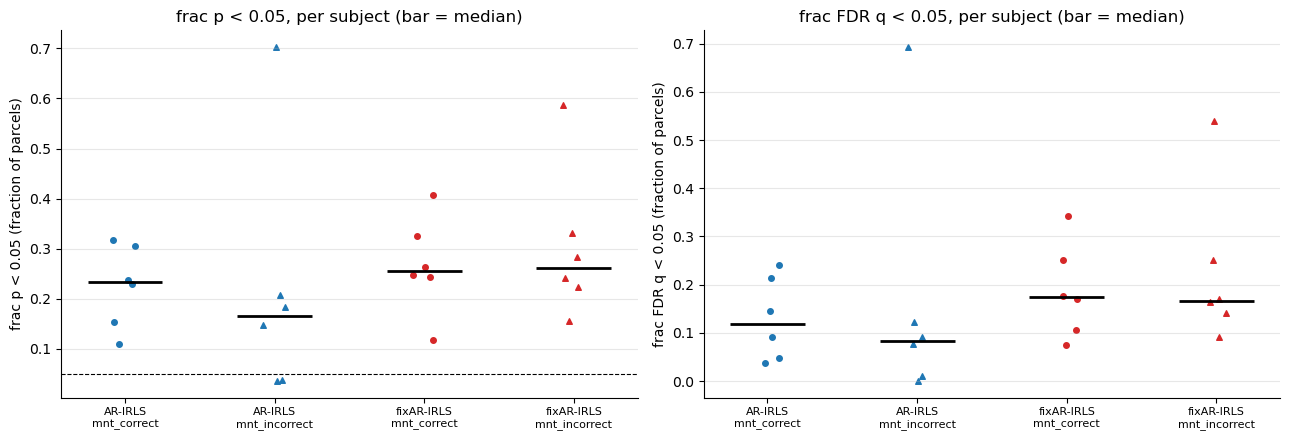

In [4]:
sig_rows = []
for s, r in res.items():
    for m in ['AR-IRLS', 'fixAR-IRLS']:
        for tt in trial_types:
            p = r['pval'][m][tt].dropna()
            sig_rows.append({'subject': s, 'model': m, 'trial type': tt,
                             'frac p < 0.05': (p < 0.05).mean(),
                             'frac FDR q < 0.05': multipletests(p, method='fdr_bh')[0].mean()})
sig_df = pd.DataFrame(sig_rows)

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
for ax, col in zip(axes, ['frac p < 0.05', 'frac FDR q < 0.05']):
    xt = []
    for i, (m, tt) in enumerate([(m, tt) for m in ['AR-IRLS', 'fixAR-IRLS'] for tt in trial_types]):
        v = sig_df.loc[(sig_df.model == m) & (sig_df['trial type'] == tt), col].values
        ax.scatter(np.full(len(v), i) + rng.uniform(-0.08, 0.08, len(v)), v, s=16, color=colors[m],
                   marker='o' if tt == 'mnt_correct' else '^')
        ax.hlines(np.median(v), i - 0.25, i + 0.25, color='k', lw=2)
        xt.append(f'{m}\n{tt}')
    ax.set_xticks(range(len(xt)), xt, fontsize=8)
    if col == 'frac p < 0.05':
        ax.axhline(0.05, color='k', lw=0.8, ls='--')
    ax.set_ylabel(f'{col} (fraction of parcels)')
    ax.set_title(f'{col}, per subject (bar = median)')
    ax.grid(alpha=0.3, axis='y'); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'ftest_frac_sig.png'), dpi=150)
plt.show()
display(sig_df.pivot_table(index='subject', columns=['model', 'trial type'], values=['frac p < 0.05', 'frac FDR q < 0.05'])
        .style.format('{:.2f}'))

**Group F-test map.** Mean over subjects of −log10(p) per parcel (higher = stronger EEG contribution), and how often each parcel has p < 0.05. The top parcels are listed per model and trial type.

In [5]:
neglog = {(m, tt): pd.DataFrame({s: -np.log10(np.clip(r['pval'][m][tt], 1e-300, None)) for s, r in res.items()})
          for m in ['AR-IRLS', 'fixAR-IRLS'] for tt in trial_types}
top = {}
for (m, tt), d in neglog.items():
    summ = pd.DataFrame({'mean -log10 p': d.mean(1), 'frac subjects p < 0.05': (d > -np.log10(0.05)).mean(1)})
    top[f'{m}, {tt}'] = summ.sort_values('mean -log10 p', ascending=False).head(10).round(2)
for k, v in top.items():
    display(v.style.set_caption(k))

,mean -log10 p,frac subjects p < 0.05
DefaultB_PFCv_4_RH,7.690000,0.500000
DefaultB_PFCv_2_LH,7.080000,0.670000
SalVentAttnB_Ins_3_RH,6.460000,0.330000
DefaultB_PFCv_3_RH,6.240000,0.330000
DorsAttnA_SPL_3_RH,5.820000,0.500000
DefaultB_PFCv_4_LH,4.810000,0.670000
DefaultB_PFCv_5_RH,4.790000,0.500000
SomMotA_18_RH,4.610000,0.670000
ContA_Temp_1_LH,4.060000,0.330000
DefaultA_PFCd_2_RH,3.940000,0.330000


,mean -log10 p,frac subjects p < 0.05
SalVentAttnB_PFCl_1_LH,14.890000,0.170000
SomMotB_S2_5_LH,14.300000,0.330000
SalVentAttnA_FrOper_4_LH,8.910000,0.170000
DefaultB_PFCv_7_LH,8.310000,0.330000
TempPar_2_LH,7.640000,0.500000
SalVentAttnA_Ins_5_LH,7.490000,0.170000
SomMotB_Aud_4_LH,6.460000,0.330000
ContA_PFClv_1_LH,6.190000,0.330000
DefaultB_Temp_4_LH,5.680000,0.500000
DorsAttnA_SPL_6_RH,5.170000,0.330000


,mean -log10 p,frac subjects p < 0.05
SalVentAttnB_PFClv_2_RH,13.680000,1.000000
ContA_PFCl_3_RH,10.480000,1.000000
ContB_PFClv_4_RH,9.570000,1.000000
ContB_PFClv_2_RH,7.680000,1.000000
ContB_PFClv_6_RH,7.610000,1.000000
ContB_PFClv_3_RH,7.470000,0.670000
ContA_PFClv_1_LH,5.720000,0.830000
DorsAttnA_SPL_11_RH,5.560000,0.830000
SomMotA_23_RH,5.180000,0.830000
SalVentAttnB_PFCl_4_LH,5.160000,0.670000


,mean -log10 p,frac subjects p < 0.05
ContA_PFClv_1_LH,11.350000,0.500000
SalVentAttnB_PFClv_2_RH,7.120000,1.000000
DefaultB_Temp_2_LH,6.920000,0.500000
SomMotA_23_RH,6.710000,0.830000
SalVentAttnB_PFCl_1_LH,6.370000,0.500000
ContA_PFCl_3_RH,6.270000,0.830000
SomMotB_Aud_4_LH,6.070000,0.500000
SomMotB_S2_8_LH,5.740000,0.500000
SomMotB_Cent_1_LH,5.370000,0.670000
SomMotA_18_RH,5.360000,0.830000


## 5. HRF agreement between models

For every parcel and trial type, `r` is the Pearson correlation between two models' HRFs over the delay axis (−2 to 18 s), so it measures agreement in **shape** only (see section 6 for amplitude). Shown: per-subject median `r` over all parcels, one panel per trial type.

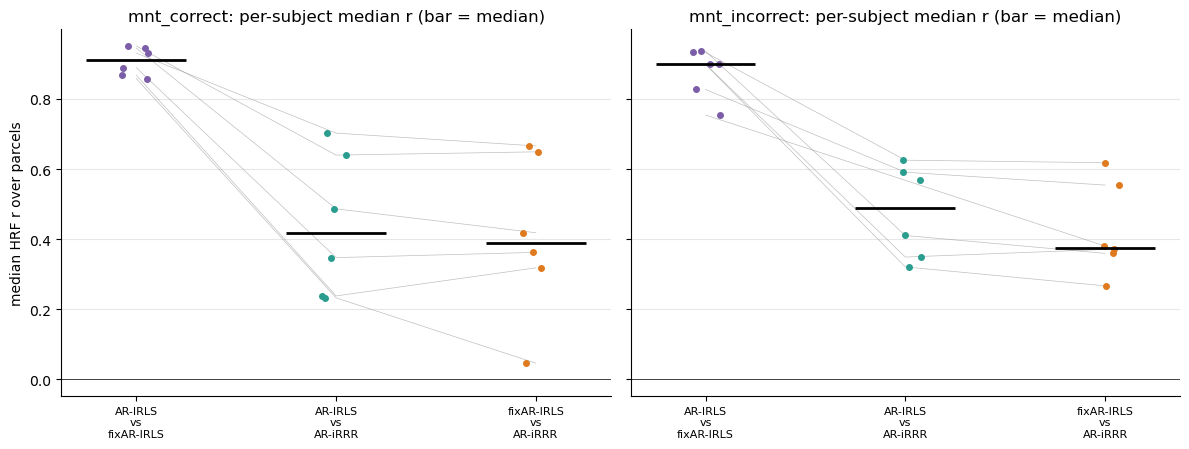

mean  median    min    max
trial type    pair                                              
mnt_correct   AR-IRLS vs AR-iRRR     0.441   0.417  0.233  0.702
              AR-IRLS vs fixAR-IRLS  0.907   0.910  0.858  0.951
              fixAR-IRLS vs AR-iRRR  0.410   0.390  0.046  0.666
mnt_incorrect AR-IRLS vs AR-iRRR     0.477   0.489  0.321  0.625
              AR-IRLS vs fixAR-IRLS  0.874   0.899  0.754  0.936
              fixAR-IRLS vs AR-iRRR  0.425   0.376  0.267  0.618

In [6]:
def corr_rows(a, b):
    """row-wise Pearson r of two (parcel x delay) arrays"""
    a = a - a.mean(1, keepdims=True); b = b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))

corr = {}   # (subject, trial type) -> DataFrame parcel x pair
for s, r in res.items():
    for tt in trial_types:
        corr[(s, tt)] = pd.DataFrame({p: corr_rows(r['hrf'][p.split(' vs ')[0]][tt].values,
                                                   r['hrf'][p.split(' vs ')[1]][tt].values) for p in pairs},
                                     index=r['parcels'])
med_corr = pd.DataFrame([{'subject': s, 'trial type': tt, 'pair': p, 'median r': d[p].median()}
                         for (s, tt), d in corr.items() for p in pairs])

fig, axes = plt.subplots(1, len(trial_types), figsize=(12, 4.6), sharey=True)
for ax, tt in zip(axes, trial_types):
    d = med_corr[med_corr['trial type'] == tt]
    wide_tt = d.pivot(index='subject', columns='pair', values='median r')[pairs]
    for _, row in wide_tt.iterrows():
        ax.plot(range(3), row.values, color='gray', lw=0.5, alpha=0.5)
    for i, p in enumerate(pairs):
        ax.scatter(np.full(len(wide_tt), i) + rng.uniform(-0.08, 0.08, len(wide_tt)), wide_tt[p], s=16, color=pair_colors[p], zorder=3)
        ax.hlines(wide_tt[p].median(), i - 0.25, i + 0.25, color='k', lw=2, zorder=4)
    ax.set_xticks(range(3), [p.replace(' vs ', '\nvs\n') for p in pairs], fontsize=8)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_title(f'{tt}: per-subject median r (bar = median)')
    ax.grid(alpha=0.3, axis='y'); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('median HRF r over parcels')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'hrf_corr.png'), dpi=150)
plt.show()
display(med_corr.groupby(['trial type', 'pair'])['median r'].agg(['mean', 'median', 'min', 'max']).round(3))

## 6. HRF amplitude

The amplitude of a parcel's HRF is its **RMS over delay**. iRRR shrinks the coefficients through the nuclear-norm penalty, and the two IRLS models whiten differently, so HRFs can agree in shape but not in size. Shown: per-subject median of the per-parcel ratio RMS(model) / RMS(AR-IRLS), per trial type.

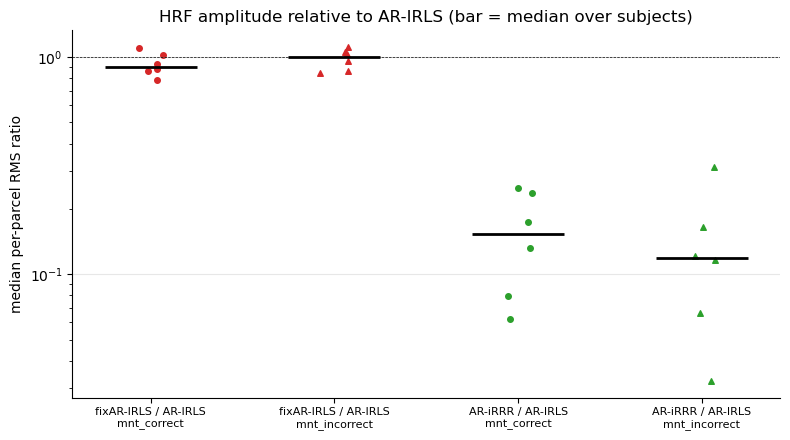

In [7]:
def rms(h):
    return np.sqrt((h.values ** 2).mean(axis=1))

ratio_rows = []
for s, r in res.items():
    for tt in trial_types:
        a_ref = rms(r['hrf']['AR-IRLS'][tt])
        row = {'subject': s, 'trial type': tt, 'median RMS AR-IRLS': np.median(a_ref)}
        for m in models[1:]:
            row[f'{m} / AR-IRLS'] = np.median(rms(r['hrf'][m][tt]) / a_ref)
        ratio_rows.append(row)
ratio_df = pd.DataFrame(ratio_rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
xt = []
for i, (m, tt) in enumerate([(m, tt) for m in models[1:] for tt in trial_types]):
    v = ratio_df.loc[ratio_df['trial type'] == tt, f'{m} / AR-IRLS'].values
    ax.scatter(np.full(len(v), i) + rng.uniform(-0.08, 0.08, len(v)), v, s=16, color=colors[m],
               marker='o' if tt == 'mnt_correct' else '^')
    ax.hlines(np.median(v), i - 0.25, i + 0.25, color='k', lw=2)
    xt.append(f'{m} / AR-IRLS\n{tt}')
ax.axhline(1, color='k', lw=0.5, ls='--')
ax.set_xticks(range(len(xt)), xt, fontsize=8)
ax.set_yscale('log')
ax.set_ylabel('median per-parcel RMS ratio')
ax.set_title('HRF amplitude relative to AR-IRLS (bar = median over subjects)')
ax.grid(alpha=0.3, axis='y'); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'hrf_amplitude.png'), dpi=150)
plt.show()
display(ratio_df.pivot(index='subject', columns='trial type').style.format('{:.3g}'))

## 7. Group HRF

Baseline-corrected HRFs. Mean ± SEM across subjects of each subject's `select_network` network-mean HRF (top) and of the HRF at `select_parcel` (bottom), one column per trial type. AR-iRRR is much smaller than the IRLS models (section 6), so each model's curve is also shown max-normalized (right two columns).

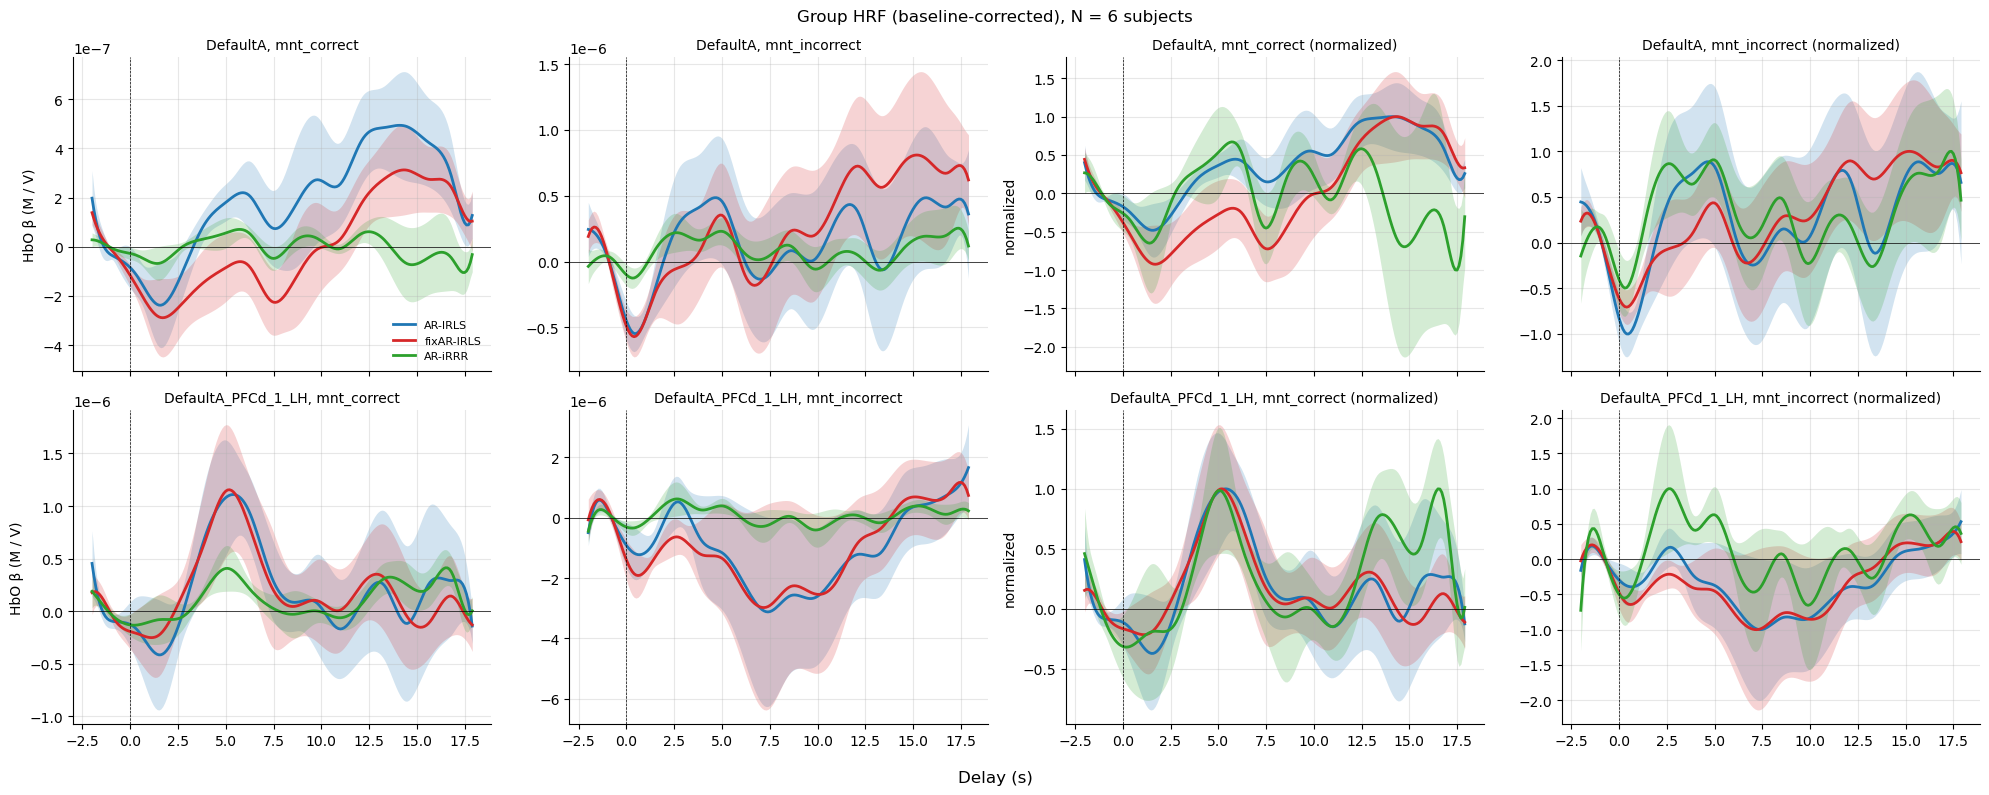

In [8]:
def net_parcels(parcels, net, hemi='both'):
    return [p for p in parcels if p.split('_')[0] == net and (hemi == 'both' or p.split('_')[-1] == hemi)]

def subj_curves(m, tt, sel):
    """subjects x delay: network-mean (sel = network name) or single-parcel (sel = parcel name) HRF"""
    out = []
    for r in res.values():
        h = r['hrf_bc'][m][tt]
        out.append(h.sel(parcel=sel).values if sel in r['parcels'] else h.sel(parcel=net_parcels(r['parcels'], sel)).mean('parcel').values)
    return np.stack(out)

fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True)
for row, sel in enumerate([select_network, select_parcel]):
    for col, (tt, is_norm) in enumerate([(tt, n) for n in [False, True] for tt in trial_types]):
        ax = axes[row, col]
        for m in models:
            h = subj_curves(m, tt, sel)
            mu, sem = h.mean(0), h.std(0, ddof=1) / np.sqrt(len(h))
            norm = np.abs(mu).max() if is_norm else 1
            ax.fill_between(hrf_t, (mu - sem) / norm, (mu + sem) / norm, color=colors[m], alpha=0.2, lw=0)
            ax.plot(hrf_t, mu / norm, color=colors[m], lw=2, label=m)
        ax.set_title(f'{sel}, {tt}' + (' (normalized)' if is_norm else ''), fontsize=10)
        ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
        ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
    axes[row, 0].set_ylabel(f'{select_chromo} β (M / V)')
    axes[row, 2].set_ylabel('normalized')
axes[0, 0].legend(fontsize=8, frameon=False)
fig.supxlabel('Delay (s)')
fig.suptitle(f'Group HRF (baseline-corrected), N = {len(subjects)} subjects')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'group_hrf.png'), dpi=150)
plt.show()

## 8. Group HRF of the 12 main networks

For each network: each subject's baseline-corrected HRF is averaged over the network's parcels, and the mean across subjects is plotted with a t-based 95% CI (`sem · t₀.₉₇₅(N−1)`). All three models are shown in each panel, max-normalized per model so the shapes can be compared. One grid per trial type. The table after each grid gives the `r` between the models' group-mean HRFs.

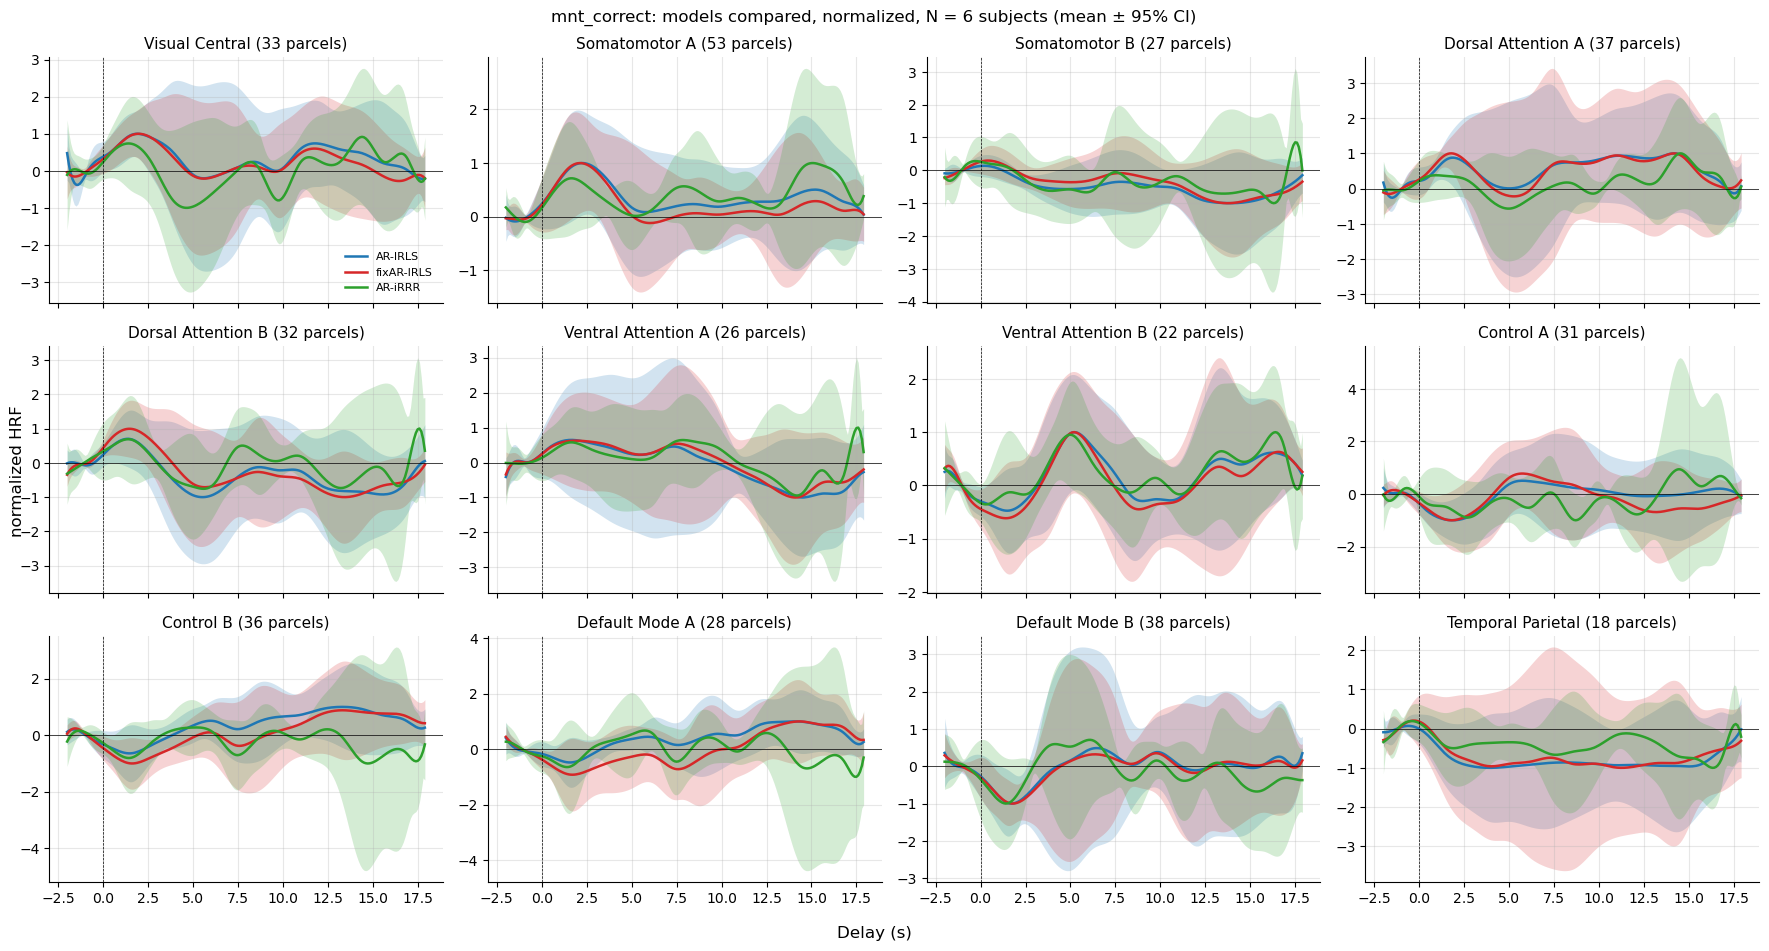

,n parcels,AR-IRLS vs fixAR-IRLS,AR-IRLS vs AR-iRRR,fixAR-IRLS vs AR-iRRR
network,,,,
VisCent,33,0.93,0.55,0.41
SomMotA,53,0.96,0.56,0.42
SomMotB,27,0.95,0.76,0.64
DorsAttnA,37,0.96,0.63,0.67
DorsAttnB,32,0.91,0.81,0.66
SalVentAttnA,26,0.98,0.79,0.83
SalVentAttnB,22,0.98,0.89,0.89
ContA,31,0.79,0.30,-0.10
ContB,36,0.91,0.15,-0.02


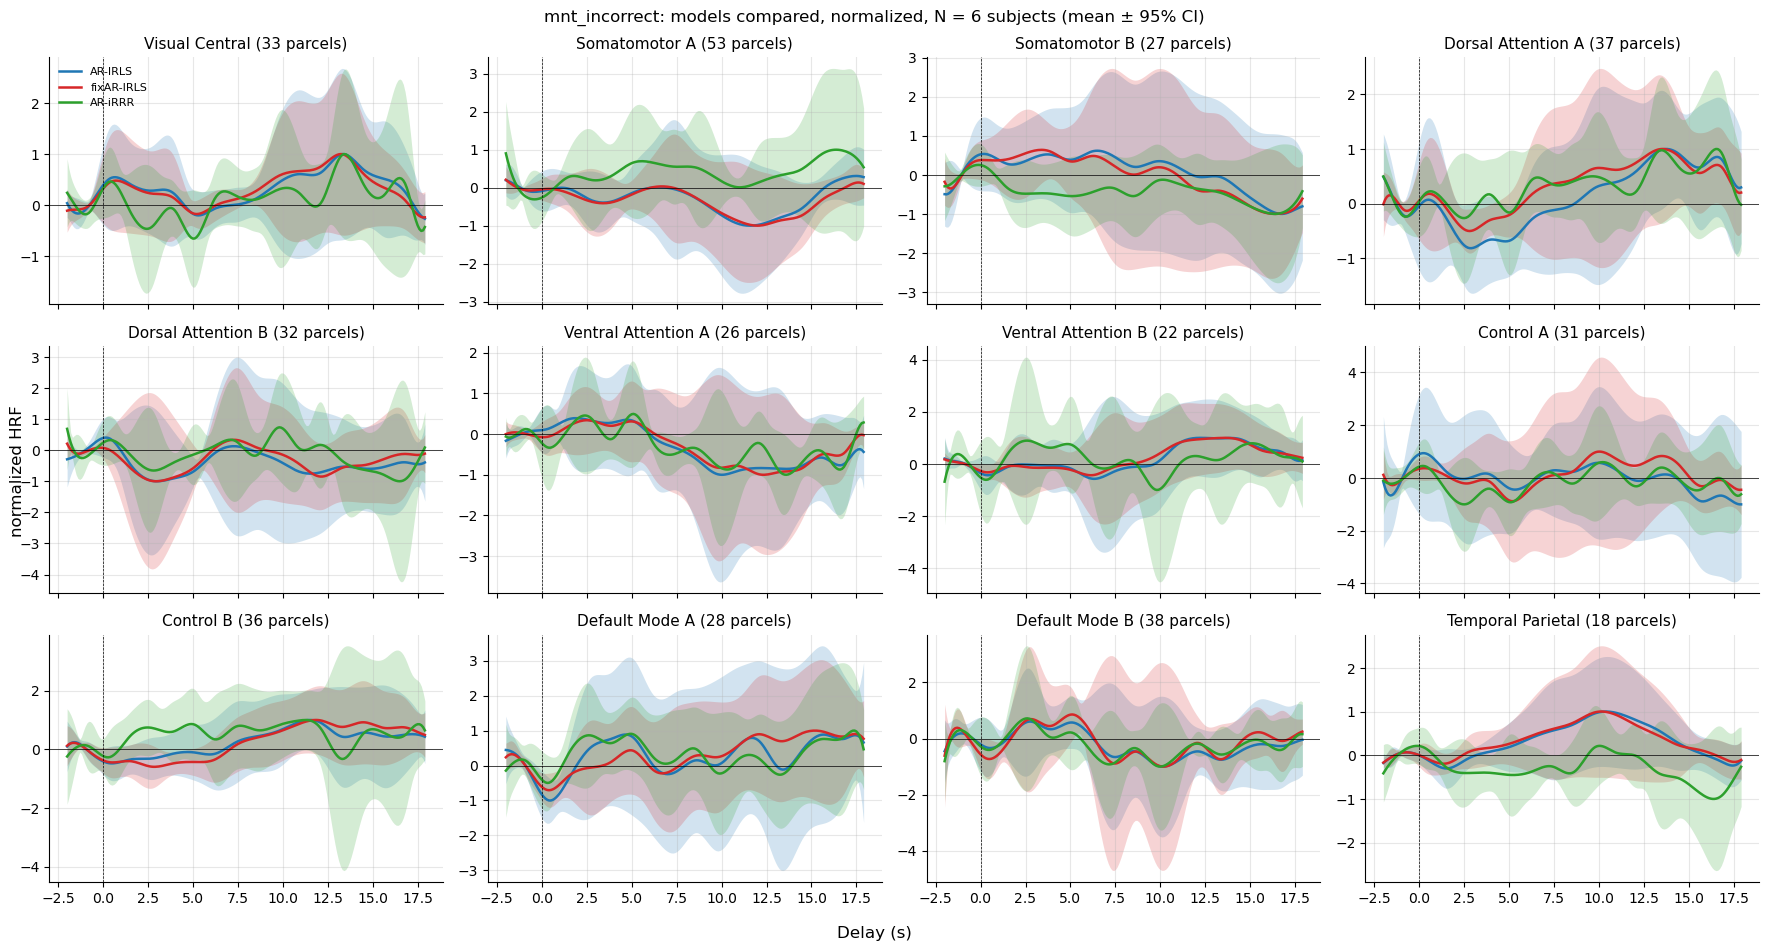

,n parcels,AR-IRLS vs fixAR-IRLS,AR-IRLS vs AR-iRRR,fixAR-IRLS vs AR-iRRR
network,,,,
VisCent,33,0.96,0.70,0.69
SomMotA,53,0.96,0.44,0.29
SomMotB,27,0.95,0.64,0.58
DorsAttnA,37,0.93,0.82,0.84
DorsAttnB,32,0.89,0.47,0.40
SalVentAttnA,26,0.96,0.85,0.84
SalVentAttnB,22,0.98,0.24,0.06
ContA,31,0.60,0.56,0.78
ContB,36,0.95,0.37,0.13


In [9]:
network_titles = {
    'VisCent': 'Visual Central', 'SomMotA': 'Somatomotor A', 'SomMotB': 'Somatomotor B',
    'DorsAttnA': 'Dorsal Attention A', 'DorsAttnB': 'Dorsal Attention B',
    'SalVentAttnA': 'Ventral Attention A', 'SalVentAttnB': 'Ventral Attention B',
    'ContA': 'Control A', 'ContB': 'Control B', 'DefaultA': 'Default Mode A', 'DefaultB': 'Default Mode B',
    'TempPar': 'Temporal Parietal',
}
network_order = list(network_titles)

def network_group_hrf(net, m, tt, hemi='both'):
    """group mean and t-based 95% CI of the subjects' baseline-corrected network-mean HRFs"""
    h = np.stack([r['hrf_bc'][m][tt].sel(parcel=net_parcels(r['parcels'], net, hemi)).mean('parcel').values
                  for r in res.values()])
    return h.mean(0), stats.sem(h, axis=0) * stats.t.ppf(0.975, len(h) - 1)

def plot_network_grid(curves, colors_map, is_norm=True, hemi='both', n_cols=4, fname=None, title=''):
    """curves: label -> (model, trial type); returns the r between the curves' group means per network"""
    n_rows = int(np.ceil(len(network_order) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 3.2 * n_rows), sharex=True)
    axs = axs.flatten()
    rows = []
    labels = list(curves)
    for ax, net in zip(axs, network_order):
        means = {}
        for lab, (m, t) in curves.items():
            mu, ci = network_group_hrf(net, m, t, hemi)
            norm = np.abs(mu).max() if is_norm else 1
            ax.fill_between(hrf_t, (mu - ci) / norm, (mu + ci) / norm, color=colors_map[lab], alpha=0.2, lw=0)
            ax.plot(hrf_t, mu / norm, color=colors_map[lab], lw=1.8, label=lab)
            means[lab] = mu
        n_par = len(net_parcels(r0['parcels'], net, hemi))
        rows.append({'network': net, 'n parcels': n_par,
                     **{f'{a} vs {b}': np.corrcoef(means[a], means[b])[0, 1]
                        for i, a in enumerate(labels) for b in labels[i + 1:]}})
        ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
        ax.set_title(f'{network_titles[net]} ({n_par} parcels)', fontsize=11)
        ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
    axs[0].legend(fontsize=8, frameon=False)
    fig.supxlabel('Delay (s)')
    fig.supylabel('normalized HRF' if is_norm else f'{select_chromo} β (M / V)')
    fig.suptitle(f'{title}, N = {len(subjects)} subjects (mean ± 95% CI)')
    fig.tight_layout()
    if fname:
        fig.savefig(os.path.join(fig_dir, fname), dpi=150)
    plt.show()
    return pd.DataFrame(rows).set_index('network')

net_corr = {}
for tt in trial_types:
    net_corr[tt] = plot_network_grid({m: (m, tt) for m in models}, colors,
                                     fname=f'group_hrf_12_networks_{tt}_norm.png', title=f'{tt}: models compared, normalized')
    display(net_corr[tt].style.format('{:.2f}', subset=pairs).background_gradient(cmap='RdBu_r', vmin=-1, vmax=1, subset=pairs)
            .set_caption(f'r between the group-mean network HRFs, {tt}'))

## 9. mnt-correct vs mnt-incorrect

The same network grid, now with the two trial types in each panel for one model at a time, **not normalized**, so the amplitudes can be compared. mnt_incorrect has far fewer trials, so its CI is wider. Change `cmp_models` to show other models.

Below the grids: per network, a paired t-test across subjects of the HRF difference (incorrect − correct) at each delay, with the delays where p < 0.05 (uncorrected) listed.

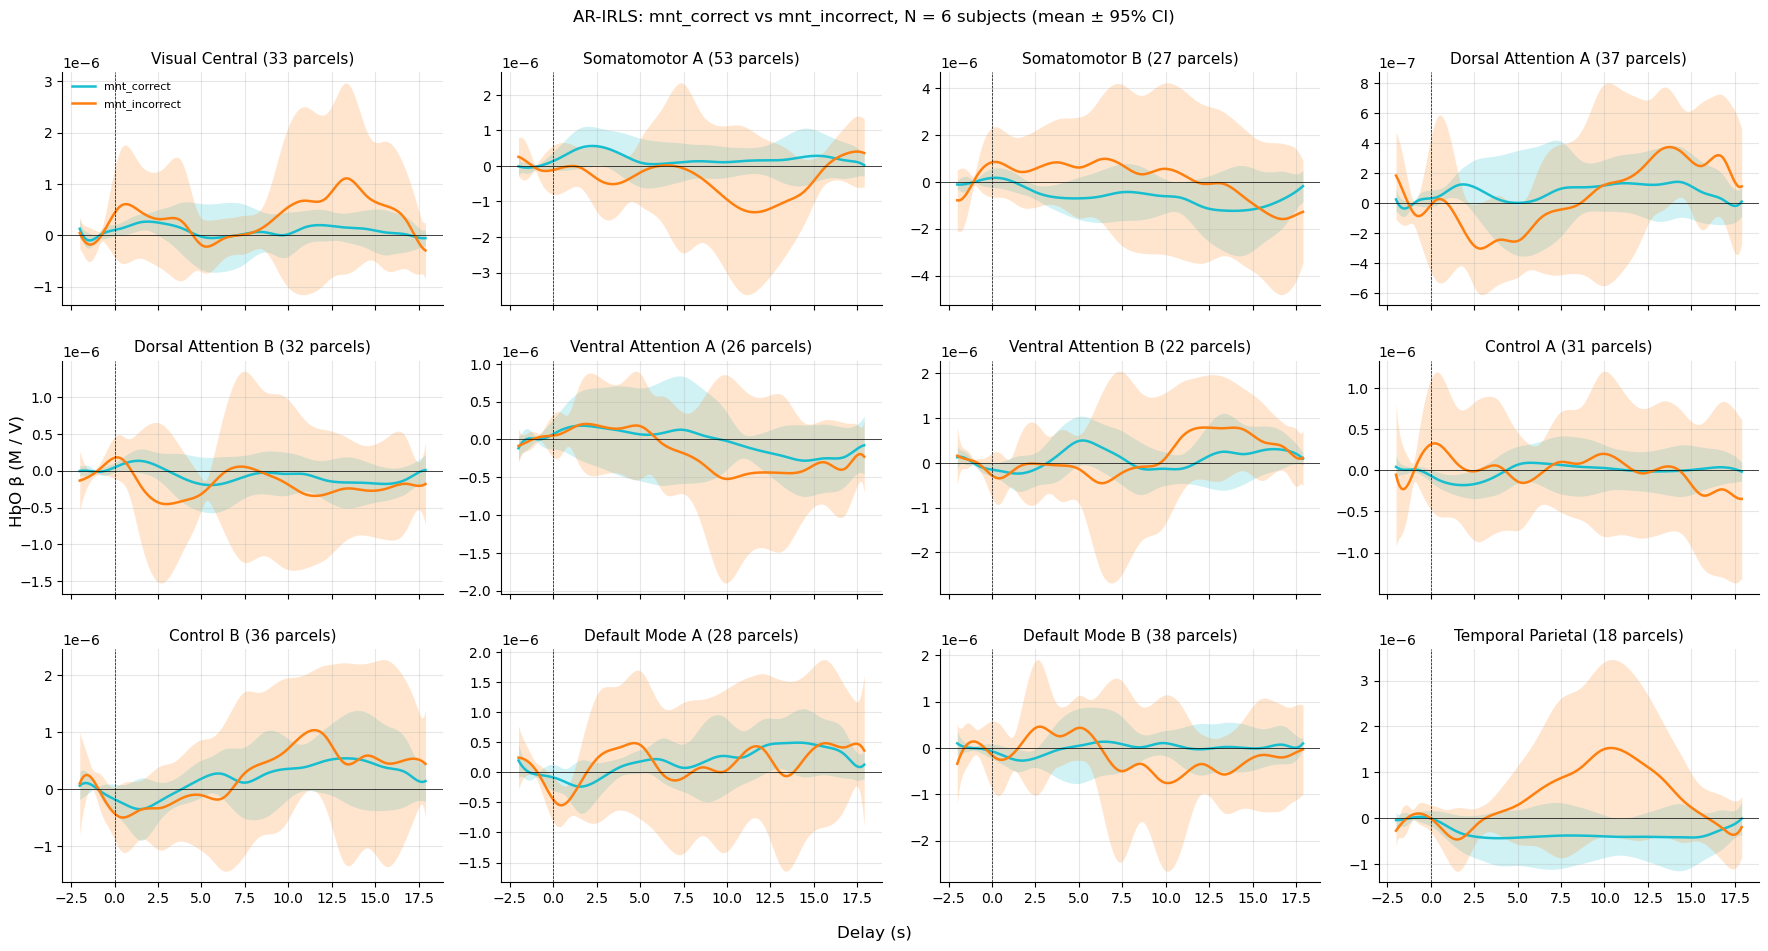

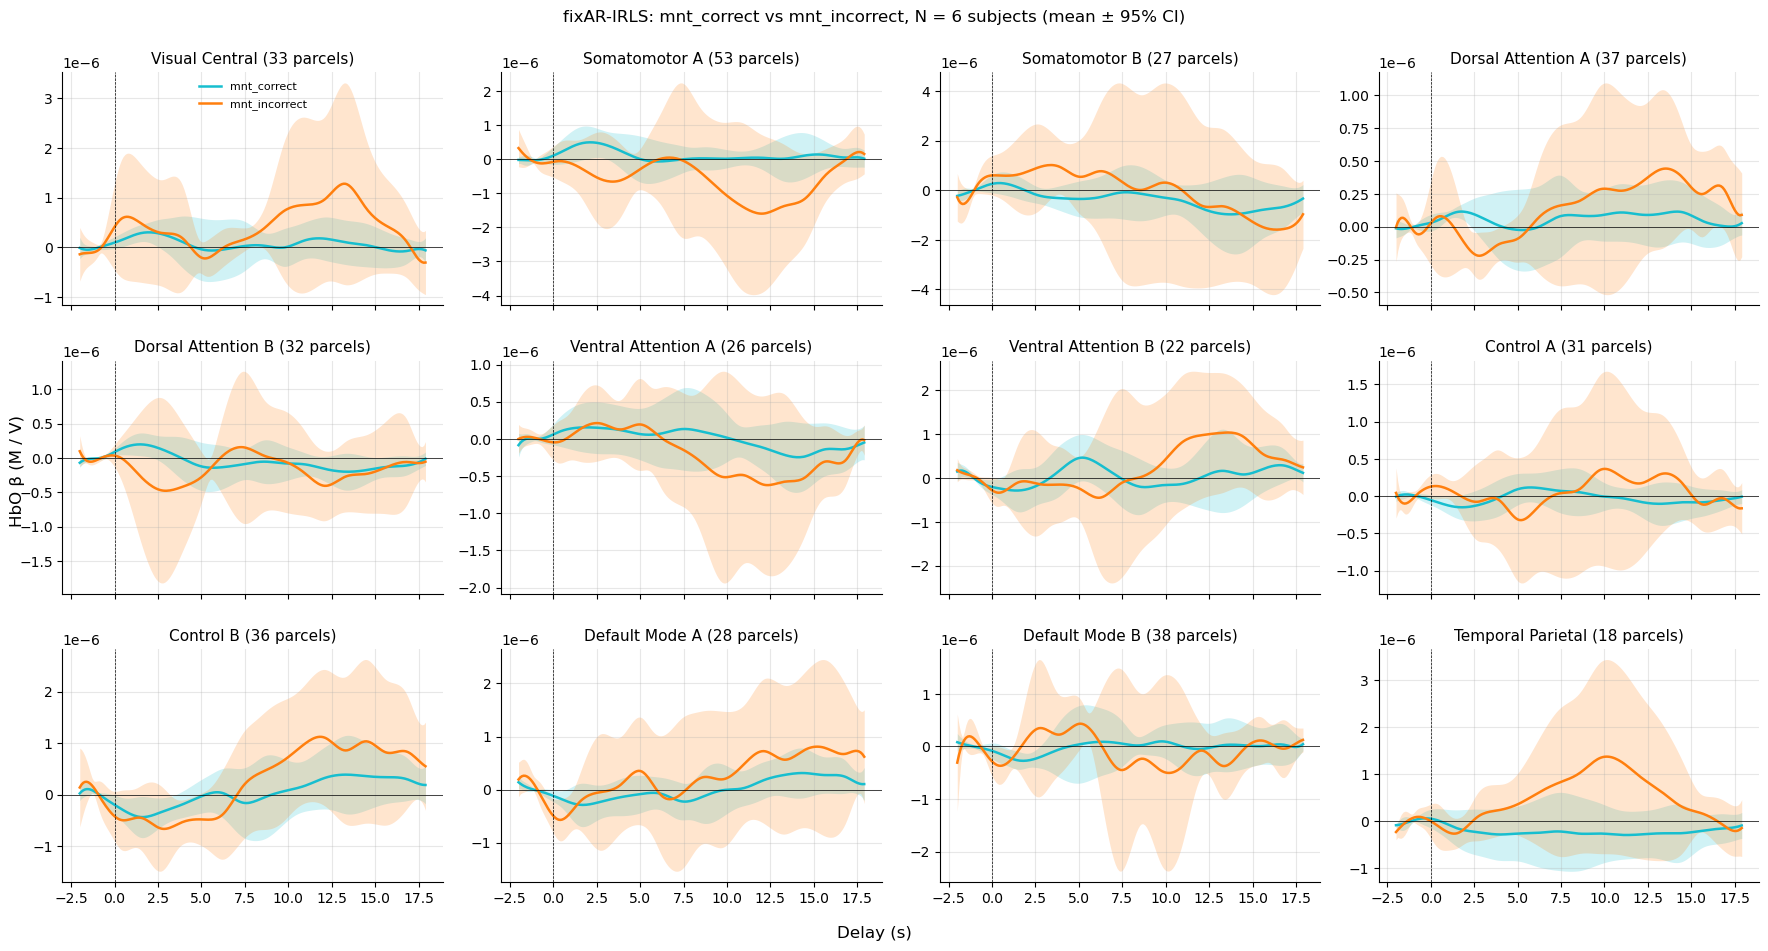

In [10]:
cmp_models = ['AR-IRLS', 'fixAR-IRLS']
for m in cmp_models:
    _ = plot_network_grid({tt: (m, tt) for tt in trial_types}, tt_colors, is_norm=False,
                          fname=f'group_hrf_12_networks_{m}_correct_vs_incorrect.png',
                          title=f'{m}: mnt_correct vs mnt_incorrect')

In [11]:
diff_rows = []
for m in cmp_models:
    for net in network_order:
        h = {tt: np.stack([r['hrf_bc'][m][tt].sel(parcel=net_parcels(r['parcels'], net)).mean('parcel').values
                           for r in res.values()]) for tt in trial_types}
        t_val, p_val = stats.ttest_rel(h['mnt_incorrect'], h['mnt_correct'], axis=0)
        sig_t = hrf_t[p_val < 0.05]
        diff_rows.append({'model': m, 'network': net, 'n delays p < 0.05': len(sig_t),
                          'delays p < 0.05 (s)': f'{sig_t.min():.1f} to {sig_t.max():.1f}' if len(sig_t) else '',
                          'min p': p_val.min()})
display(pd.DataFrame(diff_rows).set_index(['model', 'network']).style.format({'min p': '{:.3g}'}))

## 10. AR-iRRR temporal components

For each trial type, the iRRR block `B_k` (20 B-splines × parcels) factors as `B_k = U S Vᵀ`. Each column of `basis · U` is a temporal component of that trial type's HRF; every parcel's iRRR HRF is a mix of these time courses. Signs are flipped so each component's largest absolute value is positive. Only components with a nonzero singular value are drawn (rank 0 = no line).

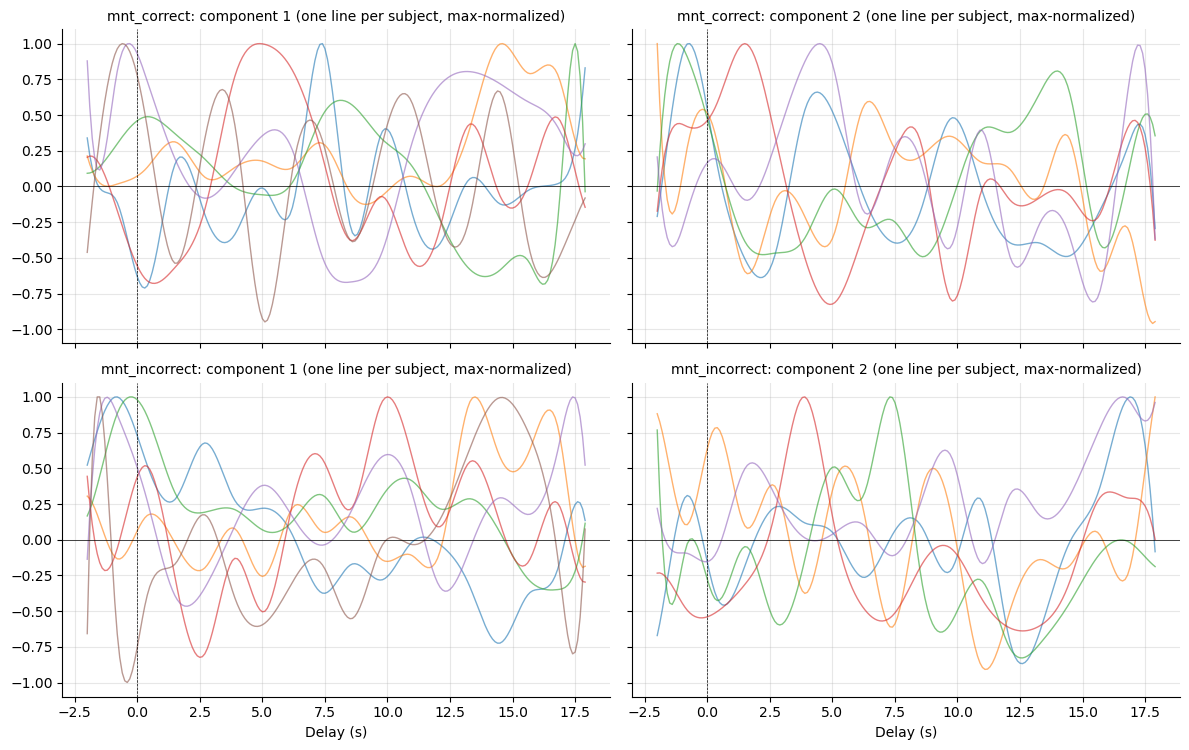

rank           share comp 1             share comp 2       \
                mean  min  max         mean    min  max         mean  min   
trial type                                                                  
mnt_correct    1.833  1.0  2.0        0.823  0.628  1.0        0.177  0.0   
mnt_incorrect  1.833  1.0  2.0        0.904  0.732  1.0        0.096  0.0   

                      
                 max  
trial type            
mnt_correct    0.372  
mnt_incorrect  0.268

In [12]:
basis_t = r0['basis'].delay_time.values
step = int(round(hrf_dt / np.diff(basis_t[:2])[0]))
comp_rows = []
fig, axes = plt.subplots(len(trial_types), 2, figsize=(12, 3.8 * len(trial_types)), sharex=True, sharey=True)
for s, r in res.items():
    basis = r['basis'].values[::step]
    for row, tt in enumerate(trial_types):
        reg = [c for c in r['irrr_betas'].regressor.values if c.startswith(f'{tt}_bspline')]
        B_k = r['irrr_betas'].sel(regressor=reg).transpose('regressor', 'parcel').values
        U, S, _ = np.linalg.svd(B_k, full_matrices=False)
        k = int(r['stats']['AR-iRRR'][f'rank_{tt}'])
        for c in range(min(k, 2)):
            tc = basis @ U[:, c]
            tc = tc * np.sign(tc[np.argmax(np.abs(tc))])
            axes[row, c].plot(basis_t[::step], tc / np.abs(tc).max(), lw=1, alpha=0.6)
        share = S ** 2 / (S ** 2).sum() if S.sum() > 0 else np.zeros_like(S)
        comp_rows.append({'subject': s, 'trial type': tt, 'rank': k, 'share comp 1': share[0], 'share comp 2': share[1]})
for row, tt in enumerate(trial_types):
    for c in range(2):
        ax = axes[row, c]
        ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
        ax.set_title(f'{tt}: component {c + 1} (one line per subject, max-normalized)', fontsize=10)
        ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel('Delay (s)')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'irrr_components.png'), dpi=150)
plt.show()
comp_df = pd.DataFrame(comp_rows)
display(comp_df.groupby('trial type')[['rank', 'share comp 1', 'share comp 2']].describe().loc[:, (slice(None), ['mean', 'min', 'max'])].round(3))

## 11. Per-subject figures

The script saves, per subject, the iRRR rank vs λ₁ curve used to pick λ₁. Pick a subject below; by default, the subjects with the highest and lowest median AR-IRLS vs fixAR-IRLS agreement (mnt_correct) are shown.

sub-723: median r over parcels (mnt_correct)
pair
AR-IRLS vs AR-iRRR       0.64
AR-IRLS vs fixAR-IRLS    0.95
fixAR-IRLS vs AR-iRRR    0.65


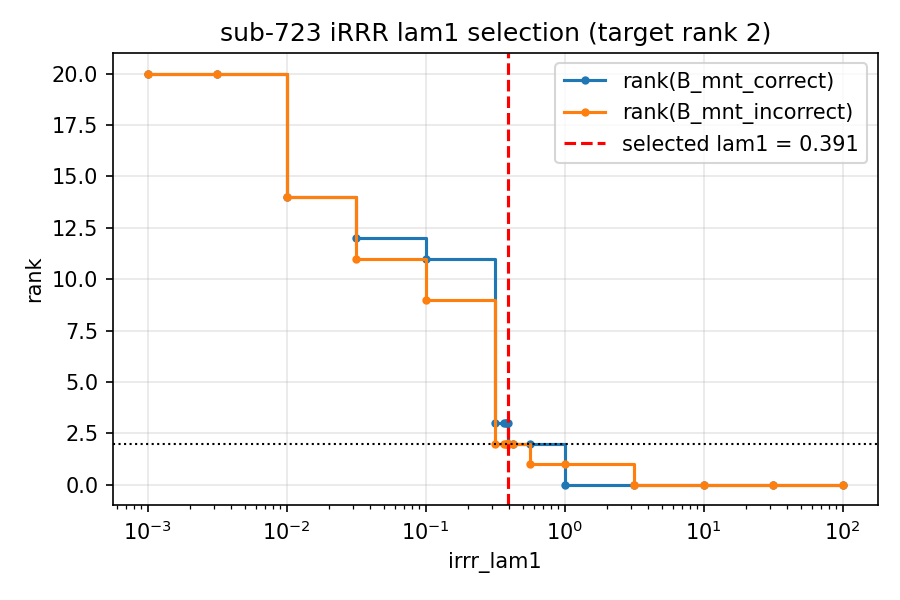

In [13]:
wide = med_corr[med_corr['trial type'] == 'mnt_correct'].pivot(index='subject', columns='pair', values='median r')

def show_subject(s):
    print(f"{s}: median r over parcels (mnt_correct)\n{wide.loc[s].round(2).to_string()}")
    png = os.path.join(plot_root, s, model_names['AR-iRRR'], f'{s}_iRRR_lam1_vs_rank.png')
    if os.path.exists(png):
        display(Image(png, width=600))

order = wide[pairs[0]].sort_values()
show_subject(order.index[-1])   # best agreement

sub-695: median r over parcels (mnt_correct)
pair
AR-IRLS vs AR-iRRR       0.23
AR-IRLS vs fixAR-IRLS    0.86
fixAR-IRLS vs AR-iRRR    0.05


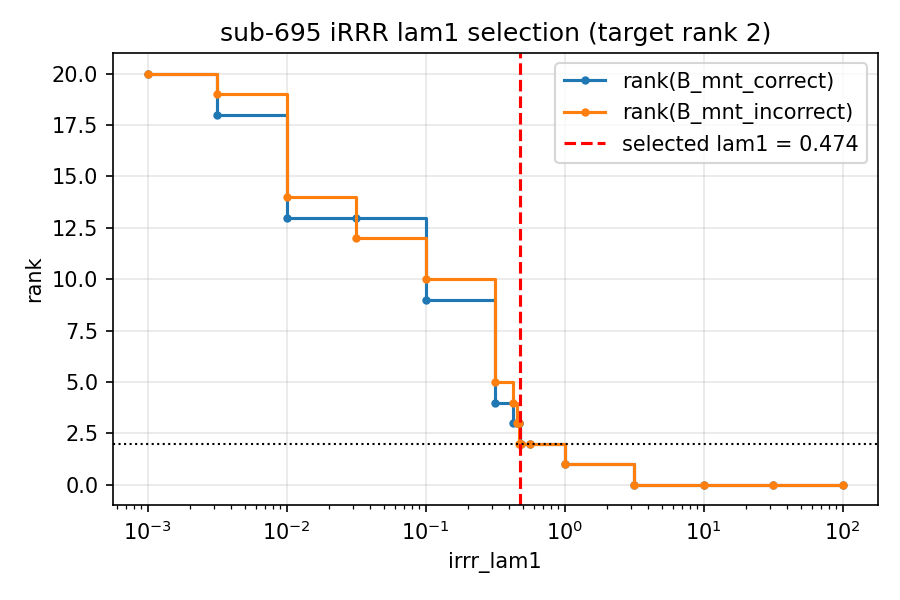

In [14]:
show_subject(order.index[0])    # worst agreement

## 12. Event-based mnt-correct HRF: network-based fixAR-IRLS and AR-iRRR

Results of `run_model_cont_EEG_mnt-correct_network-based.py`. This is a different model from sections 2–11:

- **Design: no EEG.** 20 consecutive Gaussian kernels (−2 to 18 s, 1 s apart, 1 s std) locked to the **mnt-correct** onsets, i.e. a standard event-related HRF in **M** (not M / V). The kernels are built on each full fNIRS run and sampled at the `Y_all` samples, so trials at the window edges keep their whole kernels.
- **Y: a different `Y_all`.** The shared `parcel_Y_all_truncated_to_trials_Hp` (per-run highpass, window from the first onset to the last onset + 15 s, drift/GSR OLS-regressed out, runs concatenated as gradcpt1, 2, 3), not the `Hp0.01` `Y_all` of sections 2–11.
- **Fit per network.** Parcels are split by network (the name before the first `_`, 17 networks). Each network gets its own spectral-whitening kernel (from the OLS residuals of its parcels) and its own `Y_scale`.
  - **AR-iRRR-net**: one iRRR per network; λ₁ = smallest penalty at which rank(B) = 2.
  - **fixAR-IRLS-net**: robust IRLS per parcel on the same network-whitened, scaled data.
- **sub-670 is not fit**: in its shared `Y_all`, runs gradcpt1 and gradcpt2 hold the same fNIRS data (r ≈ 0.9999 on the overlapping samples), so the script skips it.

As in sections 7–9, the HRF plots are baseline-corrected (mean over the negative delays subtracted); the statistics use the uncorrected HRFs.

In [15]:
# must match run_model_cont_EEG_mnt-correct_network-based.py
ev_reg_type = 'mnt-correct_gauss_3-stage'
ev_hp_flag = 'Hp'
ev_model_names = {'fixAR-IRLS-net': f'{ev_reg_type}_fixAR-IRLS-network{scale_tag}_{ev_hp_flag}',
                  'AR-iRRR-net': f'{ev_reg_type}_AR-iRRR-network{scale_tag}_{ev_hp_flag}'}
ev_models = list(ev_model_names)
ev_colors = {'fixAR-IRLS-net': 'C3', 'AR-iRRR-net': 'C2'}
ev_fig_dir = os.path.join(plot_root, 'group', ev_reg_type, 'summary_nb')
os.makedirs(ev_fig_dir, exist_ok=True)

def ev_prefix(subject, m):
    return os.path.join(eeg_der_dir, subject, f'{subject}_{ev_model_names[m]}')

res_ev = {}
for s in subjects_all:
    paths = {m: (get_betas_path(ev_prefix(s, m)), get_stats_path(ev_prefix(s, m))) for m in ev_models}
    if not all(os.path.exists(b) and os.path.exists(st) for b, st in paths.values()):
        continue
    r = {'hrf': {}, 'hrf_bc': {}, 'stats': {}}
    for m, (b_path, st_path) in paths.items():
        b, st = load_pickle(b_path), load_pickle(st_path)
        h = b['betas_hrf'].sel(chromo=select_chromo).rename(time='delay').drop_vars('network')
        r['hrf'][m] = h
        r['hrf_bc'][m] = h - h.sel(delay=h.delay < 0).mean('delay')
        r['stats'][m] = {k: v for k, v in st.items() if k not in ('f_test_full_noHRF', 'whiten_kernel_fft', 'acf_kernel')}
        if m == 'fixAR-IRLS-net':
            r['pval'] = pd.Series({p: float(f.pvalue) for p, f in st['f_test_full_noHRF'].items()})
    r['parcels'] = r['hrf'][ev_models[0]].parcel.values
    r['networks'] = list(r['stats']['AR-iRRR-net']['networks'])
    res_ev[s] = r

ev_subjects = list(res_ev)
ev_t = res_ev[ev_subjects[0]]['hrf'][ev_models[0]].delay.values
print(f"{len(ev_subjects)} subjects: {ev_subjects}")
print(f"not fit here but in sections 2-11: {sorted(set(subjects) - set(ev_subjects))}")
print(f"parcels per subject: {sorted({len(r['parcels']) for r in res_ev.values()})}; "
      f"delays: {ev_t[0]:.2f} to {ev_t[-1]:.2f} s ({len(ev_t)} samples, dt = {np.diff(ev_t[:2])[0]:.4f} s)")

5 subjects: ['sub-695', 'sub-721', 'sub-723', 'sub-726', 'sub-730']
not fit here but in sections 2-11: ['sub-670']
parcels per subject: [417]; delays: -2.11 to 18.02 s (182 samples, dt = 0.1112 s)


### 12a. Fit summary
- `irrr_lam1`: the selected λ₁ per subject and network (on the scaled `Y`, so comparable across networks).
- `hit rank 2`: networks whose selected fit has exactly the target rank.
- `Y_scale`: std of the network's whitened `Y` (M), shared by both models.

In [16]:
ev_irrr = {s: r['stats']['AR-iRRR-net'] for s, r in res_ev.items()}
lam_df = pd.DataFrame({s: st['irrr_lam1'] for s, st in ev_irrr.items()}).T
hit_df = pd.DataFrame({s: {n: st['rank'][n] == st['target_rank'][n] for n in st['networks']} for s, st in ev_irrr.items()}).T
yscale_df = pd.DataFrame({s: st['Y_scale'] for s, st in ev_irrr.items()}).T
print(f"fits at the target rank: {int(hit_df.values.sum())} / {hit_df.size} (subject x network)")
display(lam_df.style.format('{:.3g}').background_gradient(cmap='viridis', axis=None)
        .set_caption('irrr_lam1 per subject and network'))
display(yscale_df.style.format('{:.2g}').background_gradient(cmap='viridis', axis=None)
        .set_caption('Y_scale (M) per subject and network'))

fits at the target rank: 85 / 85 (subject x network)


,ContA,ContB,ContC,DefaultA,DefaultB,DefaultC,DorsAttnA,DorsAttnB,LimbicA,LimbicB,SalVentAttnA,SalVentAttnB,SomMotA,SomMotB,TempPar,VisCent,VisPeri
sub-695,0.562,0.422,0.133,0.422,0.487,0.178,0.562,0.422,0.0237,0.0237,0.237,0.422,0.316,0.316,0.237,0.316,0.237
sub-721,0.422,0.422,0.1,0.422,0.422,0.178,0.316,0.316,0.01,0.0316,0.274,0.487,0.365,0.237,0.316,0.422,0.075
sub-723,0.649,0.422,0.133,0.562,0.422,0.237,0.562,0.422,0.0316,0.075,0.237,0.422,0.316,0.316,0.237,0.422,0.133
sub-726,0.562,0.316,0.133,0.422,0.316,0.178,0.365,0.422,0.0133,0.0237,0.237,0.316,0.237,0.237,0.316,0.316,0.0562
sub-730,0.487,0.562,0.0237,0.316,0.562,0.1,0.316,0.422,0.0316,0.0178,0.237,0.365,0.237,0.316,0.316,0.316,0.1


,ContA,ContB,ContC,DefaultA,DefaultB,DefaultC,DorsAttnA,DorsAttnB,LimbicA,LimbicB,SalVentAttnA,SalVentAttnB,SomMotA,SomMotB,TempPar,VisCent,VisPeri
sub-695,1.3e-08,3.1e-08,1.3e-09,1.9e-08,2.2e-08,1.8e-08,6.7e-09,1.9e-08,1.2e-10,7.9e-09,2.1e-08,2.3e-08,2e-08,2.7e-08,1.6e-08,1.7e-08,3.9e-09
sub-721,1.2e-08,2.1e-08,1e-09,1.3e-08,1.8e-08,8.7e-09,3.7e-09,1.3e-08,2.3e-10,4.5e-09,1.5e-08,1.8e-08,1.4e-08,2.4e-08,1.3e-08,9e-09,1.9e-09
sub-723,1.3e-08,2.7e-08,1.8e-09,1.8e-08,3e-08,2.1e-08,8.7e-09,1.8e-08,1.4e-10,6.3e-09,3.2e-08,3.1e-08,2.6e-08,2.1e-08,1.5e-08,2e-08,4.4e-09
sub-726,1.3e-08,2.7e-08,6.1e-10,1.7e-08,2.8e-08,2.4e-08,7.8e-09,1.6e-08,2.3e-10,4.6e-09,2.2e-08,2.7e-08,1.4e-08,3.2e-08,2.4e-08,2.2e-08,4.4e-09
sub-730,1.1e-08,2.3e-08,1.8e-09,2.6e-08,2.6e-08,2.2e-08,6.3e-09,1.3e-08,1.5e-10,1.9e-08,2.2e-08,2.6e-08,1.2e-08,1.8e-08,1.4e-08,1.8e-08,3.8e-09


### 12b. mnt-correct HRF: F-tests (fixAR-IRLS-net)

Per parcel, the script tests whether the 20 kernel betas are jointly zero (`f_test_full_noHRF`). iRRR has no F-test. Per subject: the fraction of parcels with p < 0.05 and with FDR (Benjamini–Hochberg over the parcels) q < 0.05. Then per network, pooled over subjects, and the top parcels by mean −log10(p).

In [17]:
ev_sig = pd.DataFrame({s: {'frac p < 0.05': (r['pval'] < 0.05).mean(),
                           'frac FDR q < 0.05': multipletests(r['pval'].dropna(), method='fdr_bh')[0].mean()}
                       for s, r in res_ev.items()}).T
display(ev_sig.style.format('{:.2f}').set_caption('fraction of parcels, per subject'))

ev_neglog = pd.DataFrame({s: -np.log10(np.clip(r['pval'], 1e-300, None)) for s, r in res_ev.items()})
ev_net_of = ev_neglog.index.map(lambda p: p.split('_')[0])
ev_net_sig = pd.DataFrame({'n parcels': ev_neglog.groupby(ev_net_of).size(),
                           'mean -log10 p': ev_neglog.groupby(ev_net_of).mean().mean(1),
                           'frac p < 0.05 (parcels x subjects)': (ev_neglog > -np.log10(0.05)).groupby(ev_net_of).mean().mean(1)})
display(ev_net_sig.sort_values('mean -log10 p', ascending=False).style.format('{:.2f}', subset=ev_net_sig.columns[1:])
        .set_caption('per network'))
ev_top = pd.DataFrame({'mean -log10 p': ev_neglog.mean(1), 'frac subjects p < 0.05': (ev_neglog > -np.log10(0.05)).mean(1)})
display(ev_top.sort_values('mean -log10 p', ascending=False).head(10).round(2).style.set_caption('top 10 parcels'))

,frac p < 0.05,frac FDR q < 0.05
sub-695,0.58,0.53
sub-721,0.24,0.15
sub-723,0.43,0.33
sub-726,0.39,0.29
sub-730,0.50,0.43


,n parcels,mean -log10 p,frac p < 0.05 (parcels x subjects)
DefaultA,28,4.75,0.52
LimbicB,5,4.11,0.64
ContB,36,3.47,0.47
ContA,31,3.29,0.49
SalVentAttnB,22,3.27,0.50
DefaultB,38,2.76,0.48
DorsAttnA,37,2.63,0.48
VisCent,33,2.45,0.48
DorsAttnB,32,1.89,0.34
VisPeri,13,1.87,0.40


,mean -log10 p,frac subjects p < 0.05
ContA_PFClv_1_LH,15.040000,1.000000
DefaultA_PFCm_7_RH,14.400000,1.000000
ContA_PFCl_3_RH,13.850000,1.000000
DefaultA_PFCm_5_RH,13.710000,0.800000
SalVentAttnB_PFClv_2_RH,12.150000,1.000000
ContB_PFClv_4_RH,10.870000,1.000000
DefaultB_PFCd_1_RH,10.240000,0.800000
ContB_PFCld_1_RH,10.200000,0.600000
ContB_PFClv_5_RH,9.840000,0.600000
DefaultA_PFCm_2_RH,9.380000,0.800000


### 12c. Agreement between fixAR-IRLS-net and AR-iRRR-net

Per parcel: Pearson `r` between the two models' HRFs over delay (shape), and the RMS ratio AR-iRRR-net / fixAR-IRLS-net (amplitude). Shown: per-subject medians over all parcels, and the median `r` per subject and network.

In [18]:
ev_agree, ev_r_net = {}, {}
for s, r in res_ev.items():
    a, b = r['hrf']['fixAR-IRLS-net'], r['hrf']['AR-iRRR-net']
    r_p = pd.Series(corr_rows(a.values, b.values), index=r['parcels'])
    ev_agree[s] = {'median r': r_p.median(), 'median RMS ratio iRRR / IRLS': np.median(rms(b) / rms(a)),
                   'median RMS fixAR-IRLS-net (M)': np.median(rms(a))}
    ev_r_net[s] = r_p.groupby(lambda p: p.split('_')[0]).median()
ev_agree = pd.DataFrame(ev_agree).T
ev_r_net = pd.DataFrame(ev_r_net).T
display(ev_agree.style.format('{:.3g}').set_caption('fixAR-IRLS-net vs AR-iRRR-net, per subject'))
display(ev_r_net.style.format('{:.2f}').background_gradient(cmap='RdBu_r', vmin=-1, vmax=1, axis=None)
        .set_caption('median r over the network parcels'))

,median r,median RMS ratio iRRR / IRLS,median RMS fixAR-IRLS-net (M)
sub-695,0.629,0.314,9.14e-10
sub-721,0.775,0.186,5.54e-10
sub-723,0.696,0.227,1.06e-09
sub-726,0.705,0.257,1.03e-09
sub-730,0.745,0.286,9.04e-10


,ContA,ContB,ContC,DefaultA,DefaultB,DefaultC,DorsAttnA,DorsAttnB,LimbicA,LimbicB,SalVentAttnA,SalVentAttnB,SomMotA,SomMotB,TempPar,VisCent,VisPeri
sub-695,0.71,0.56,0.76,0.71,0.42,0.88,0.68,0.58,0.45,0.94,0.54,0.77,0.46,0.65,0.57,0.82,0.40
sub-721,0.64,0.71,0.97,0.88,0.65,0.74,0.79,0.42,0.95,0.95,0.76,0.60,0.88,0.71,0.84,0.76,0.62
sub-723,0.59,0.58,0.97,0.89,0.53,0.92,0.76,0.74,0.86,0.98,0.38,0.67,0.49,0.74,0.69,0.83,0.88
sub-726,0.68,0.66,0.70,0.71,0.73,0.82,0.37,0.67,0.89,0.95,0.53,0.61,0.94,0.87,0.71,0.54,0.67
sub-730,0.72,0.65,0.97,0.76,0.43,0.87,0.61,0.66,0.92,0.99,0.85,0.50,0.71,0.85,0.92,0.89,0.90


### 12d. Group HRF of the 12 main networks

Same layout as section 8: each subject's baseline-corrected HRF averaged over the network's parcels, mean across subjects ± t-based 95% CI. First in M (not normalized), then max-normalized per model so the shapes can be compared. The table gives the `r` between the models' group-mean HRFs.

`plot_curve_grid` takes, per curve, a function `net -> (delay, mean, CI)`, so curves on different delay grids (the event-based models are on the fNIRS grid, the EEG-weighted ones on `hrf_dt`) can share a panel; `r` is computed after interpolating onto `hrf_t`.

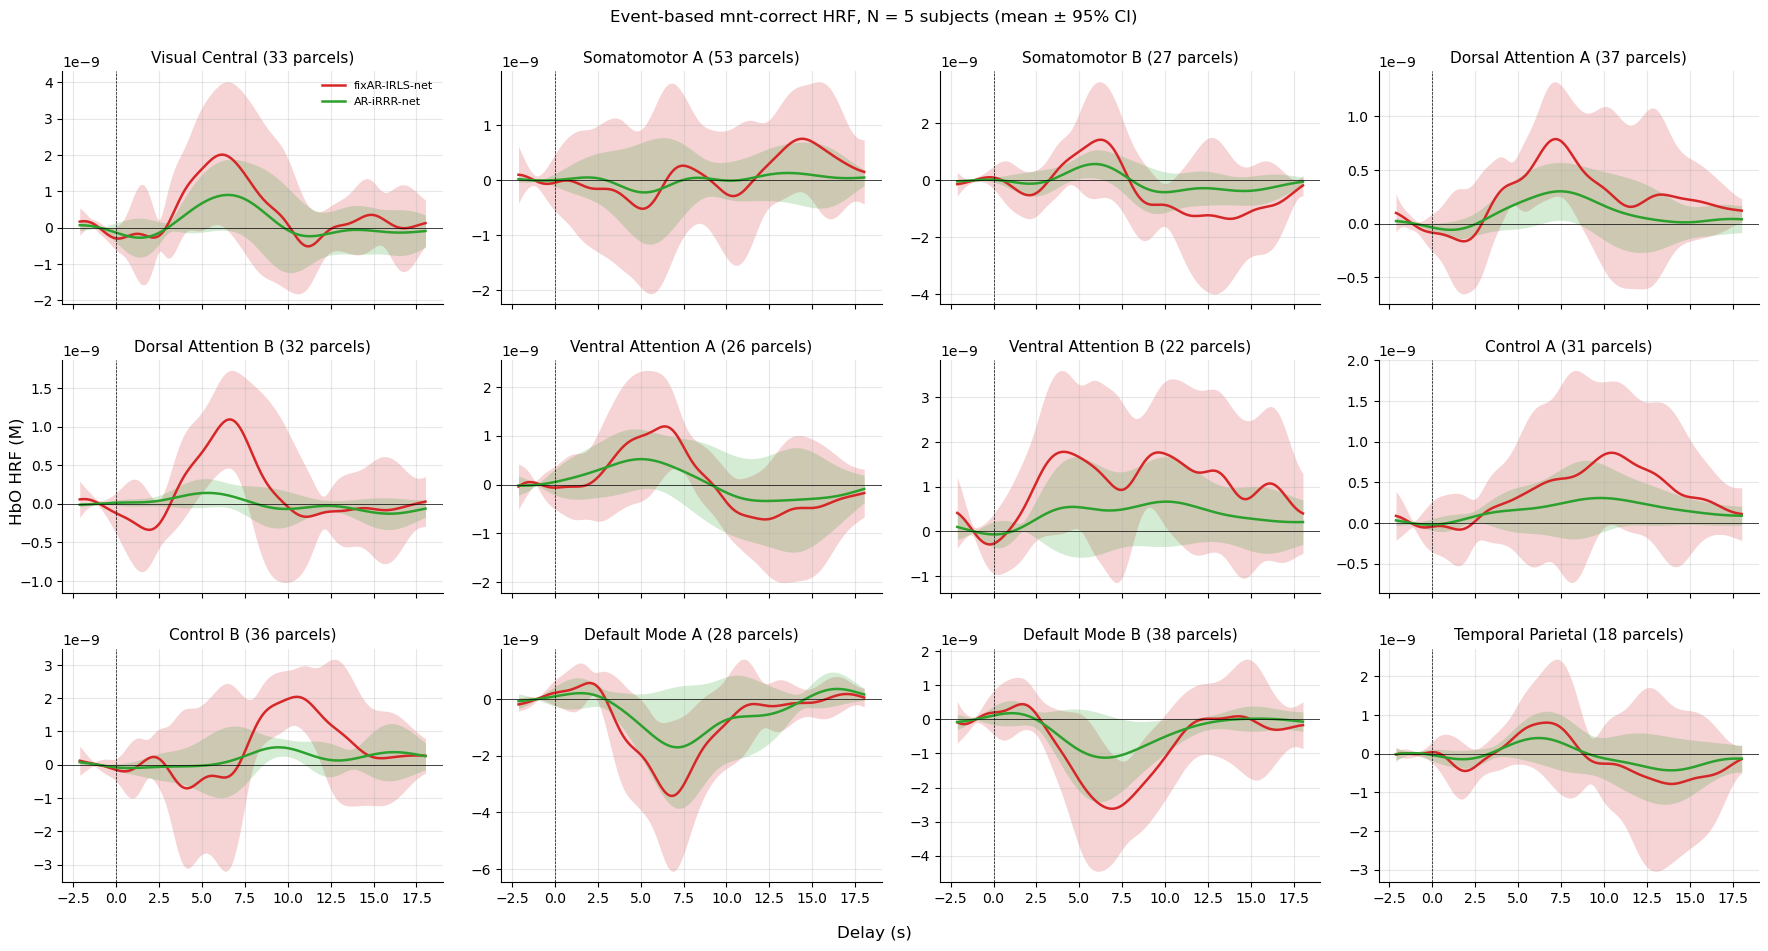

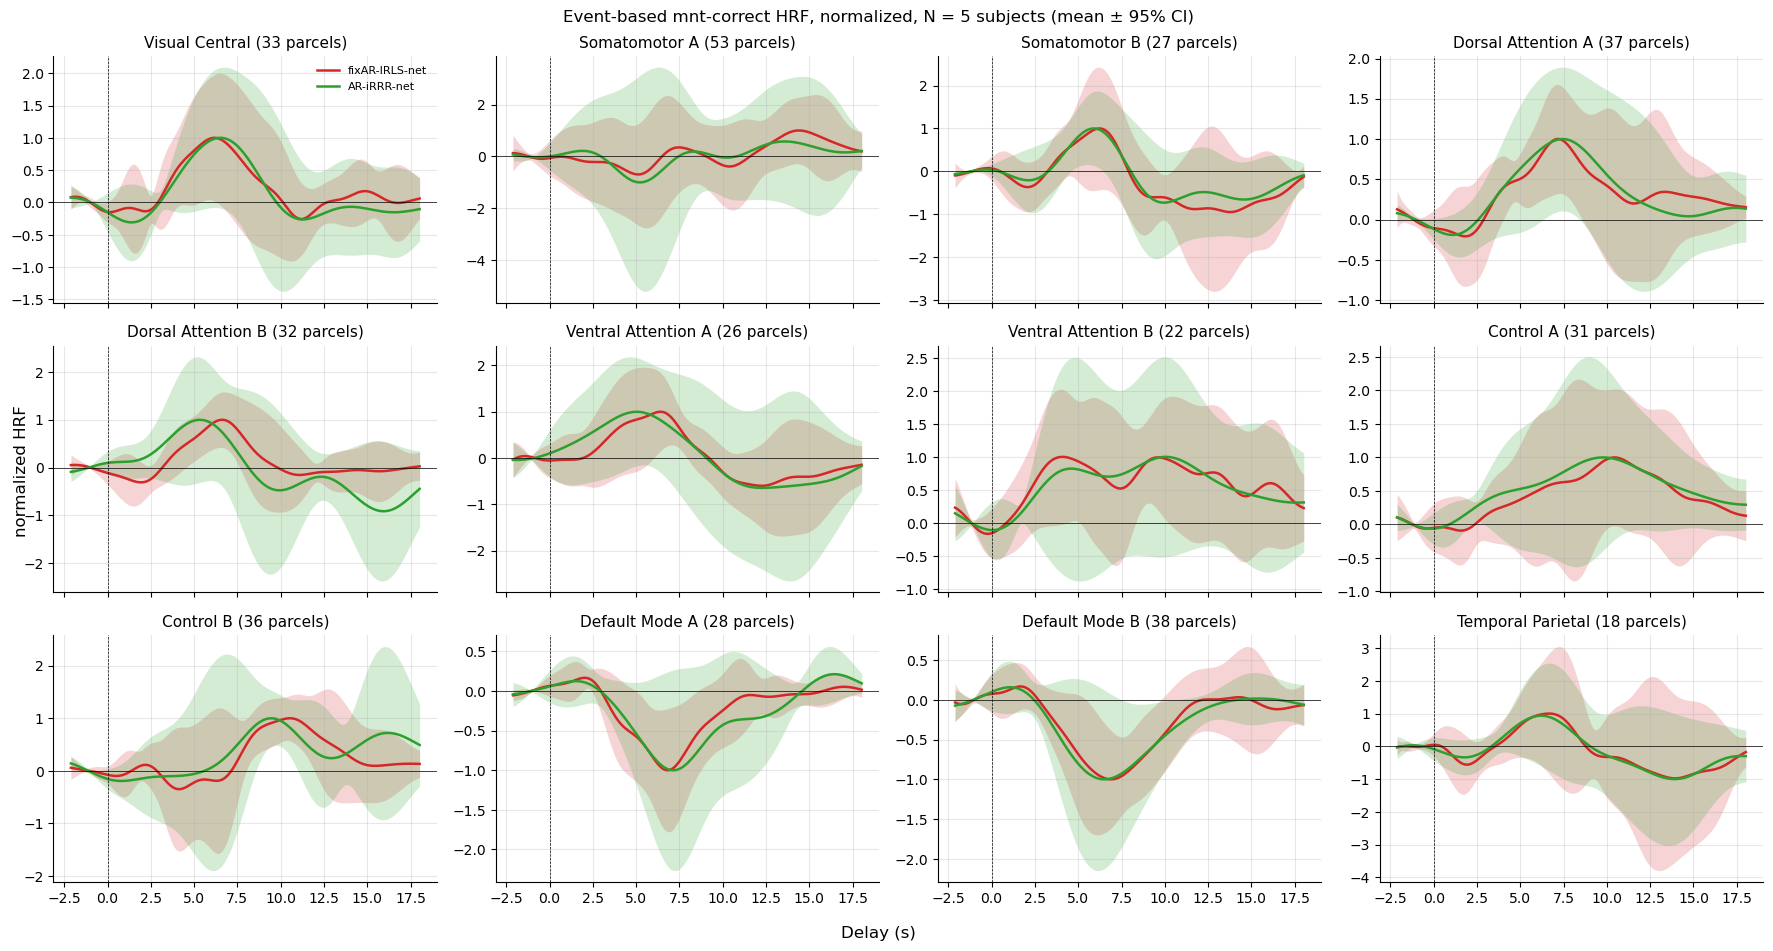

,n parcels,fixAR-IRLS-net vs AR-iRRR-net
network,,
VisCent,33,0.97
SomMotA,53,0.78
SomMotB,27,0.98
DorsAttnA,37,0.94
DorsAttnB,32,0.63
SalVentAttnA,26,0.94
SalVentAttnB,22,0.94
ContA,31,0.97
ContB,36,0.74


In [19]:
def group_mean_ci(h):
    return h.mean(0), stats.sem(h, axis=0) * stats.t.ppf(0.975, len(h) - 1)

def ev_net_curve(m, subj=None):
    """net -> (delay, group mean, 95% CI) of the event-based model m, over subj (default: all)"""
    subj = subj or ev_subjects
    return lambda net: (ev_t, *group_mean_ci(np.stack(
        [res_ev[s]['hrf_bc'][m].sel(parcel=net_parcels(res_ev[s]['parcels'], net)).mean('parcel').values for s in subj])))

def eeg_net_curve(m, tt, subj=None):
    """same for the EEG-weighted model m and trial type tt of sections 2-11"""
    subj = subj or subjects
    return lambda net: (hrf_t, *group_mean_ci(np.stack(
        [res[s]['hrf_bc'][m][tt].sel(parcel=net_parcels(res[s]['parcels'], net)).mean('parcel').values for s in subj])))

def plot_curve_grid(curves, colors_map, is_norm, ylabel, title, fname=None, n_cols=4):
    """curves: label -> (net -> (delay, mean, CI)); returns the r between the curves' group means per network"""
    n_rows = int(np.ceil(len(network_order) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 3.2 * n_rows), sharex=True)
    axs = axs.flatten()
    labels, rows = list(curves), []
    for ax, net in zip(axs, network_order):
        means = {}
        for lab, f in curves.items():
            t, mu, ci = f(net)
            norm = np.abs(mu).max() if is_norm else 1
            ax.fill_between(t, (mu - ci) / norm, (mu + ci) / norm, color=colors_map[lab], alpha=0.2, lw=0)
            ax.plot(t, mu / norm, color=colors_map[lab], lw=1.8, label=lab)
            means[lab] = np.interp(hrf_t, t, mu)
        n_par = len(net_parcels(res_ev[ev_subjects[0]]['parcels'], net))
        rows.append({'network': net, 'n parcels': n_par,
                     **{f'{a} vs {b}': np.corrcoef(means[a], means[b])[0, 1]
                        for i, a in enumerate(labels) for b in labels[i + 1:]}})
        ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
        ax.set_title(f'{network_titles[net]} ({n_par} parcels)', fontsize=11)
        ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
    axs[0].legend(fontsize=8, frameon=False)
    fig.supxlabel('Delay (s)')
    fig.supylabel(ylabel)
    fig.suptitle(f'{title} (mean ± 95% CI)')
    fig.tight_layout()
    if fname:
        fig.savefig(os.path.join(ev_fig_dir, fname), dpi=150)
    plt.show()
    return pd.DataFrame(rows).set_index('network')

def show_r_table(df, caption):
    cols = [c for c in df.columns if ' vs ' in c]
    display(df.style.format('{:.2f}', subset=cols).background_gradient(cmap='RdBu_r', vmin=-1, vmax=1, subset=cols)
            .set_caption(caption))

ev_curves = {m: ev_net_curve(m) for m in ev_models}
_ = plot_curve_grid(ev_curves, ev_colors, is_norm=False, ylabel=f'{select_chromo} HRF (M)',
                    title=f'Event-based mnt-correct HRF, N = {len(ev_subjects)} subjects',
                    fname='group_hrf_12_networks.png')
ev_net_corr = plot_curve_grid(ev_curves, ev_colors, is_norm=True, ylabel='normalized HRF',
                              title=f'Event-based mnt-correct HRF, normalized, N = {len(ev_subjects)} subjects',
                              fname='group_hrf_12_networks_norm.png')
show_r_table(ev_net_corr, 'r between the group-mean network HRFs, fixAR-IRLS-net vs AR-iRRR-net')

### 12e. Event-based vs EEG-weighted mnt-correct HRF

The event-based HRF (this section) is the mean fNIRS response to an mnt-correct trial; the EEG-weighted `mnt_correct` HRF of sections 2–11 is the fNIRS response per unit of within-trial Cz EEG. If the EEG regressor mostly carries the trial timing, the two should have similar shapes. Only the subjects in both sets are used, all curves are max-normalized (the units differ: M vs M / V), and `Y_all` differs between the two scripts (see the start of section 12).

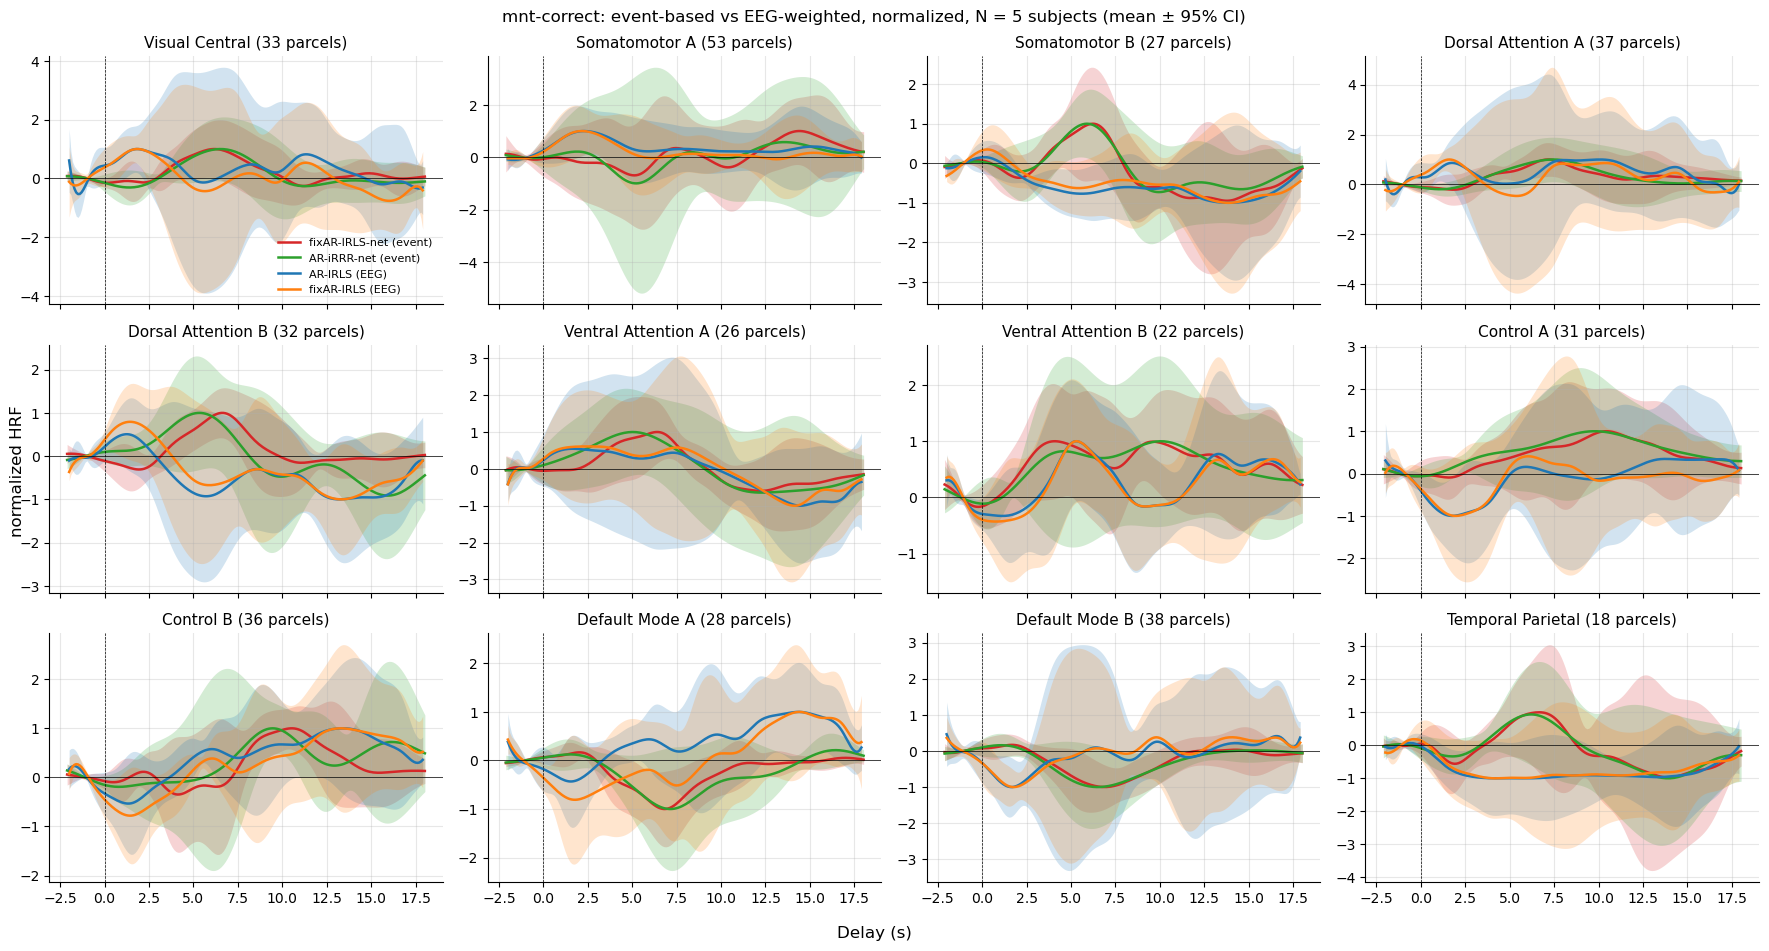

,n parcels,fixAR-IRLS-net (event) vs AR-iRRR-net (event),fixAR-IRLS-net (event) vs AR-IRLS (EEG),fixAR-IRLS-net (event) vs fixAR-IRLS (EEG),AR-iRRR-net (event) vs AR-IRLS (EEG),AR-iRRR-net (event) vs fixAR-IRLS (EEG),AR-IRLS (EEG) vs fixAR-IRLS (EEG)
network,,,,,,,
VisCent,33,0.97,-0.35,-0.39,-0.28,-0.30,0.91
SomMotA,53,0.78,-0.20,-0.32,-0.02,-0.04,0.95
SomMotB,27,0.98,0.26,0.37,0.17,0.27,0.95
DorsAttnA,37,0.94,0.23,-0.09,0.30,0.01,0.90
DorsAttnB,32,0.63,-0.38,-0.32,0.13,0.28,0.95
SalVentAttnA,26,0.94,0.73,0.74,0.86,0.86,0.99
SalVentAttnB,22,0.94,0.35,0.38,0.28,0.31,0.99
ContA,31,0.97,0.45,0.50,0.34,0.44,0.83
ContB,36,0.74,0.52,0.44,0.68,0.66,0.96


In [20]:
both_subj = [s for s in ev_subjects if s in res]
cmp_curves = {'fixAR-IRLS-net (event)': ev_net_curve('fixAR-IRLS-net', both_subj),
              'AR-iRRR-net (event)': ev_net_curve('AR-iRRR-net', both_subj),
              'AR-IRLS (EEG)': eeg_net_curve('AR-IRLS', 'mnt_correct', both_subj),
              'fixAR-IRLS (EEG)': eeg_net_curve('fixAR-IRLS', 'mnt_correct', both_subj)}
cmp_colors = dict(zip(cmp_curves, ['C3', 'C2', 'C0', 'C1']))
cmp_corr = plot_curve_grid(cmp_curves, cmp_colors, is_norm=True, ylabel='normalized HRF',
                           title=f'mnt-correct: event-based vs EEG-weighted, normalized, N = {len(both_subj)} subjects',
                           fname='group_hrf_12_networks_event_vs_eeg_norm.png')
show_r_table(cmp_corr, 'r between the group-mean network HRFs (event-based vs EEG-weighted)')

### 12f. Per-subject HRFs

The `select_network` network-mean HRF (baseline-corrected, in M) of every subject, for both models, and that subject's iRRR rank vs λ₁ curve for the same network.

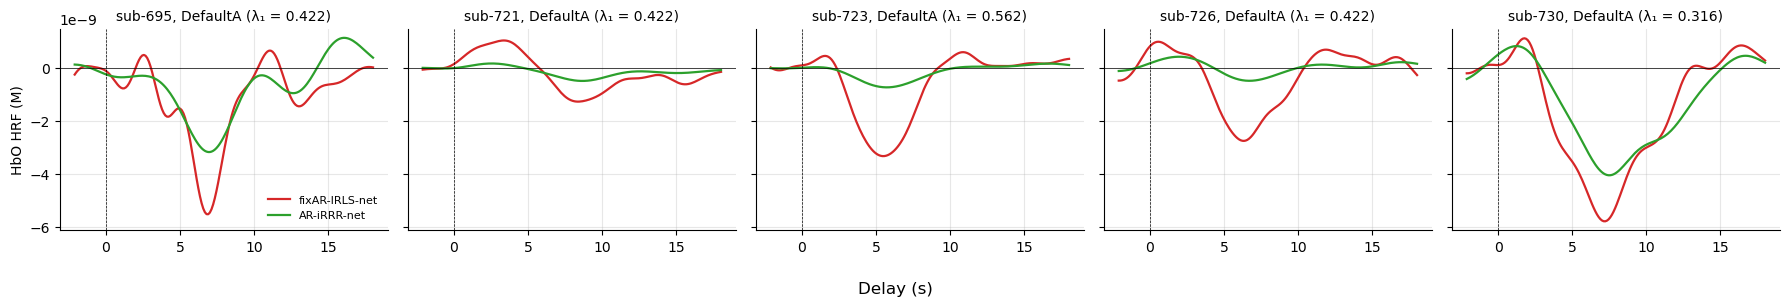

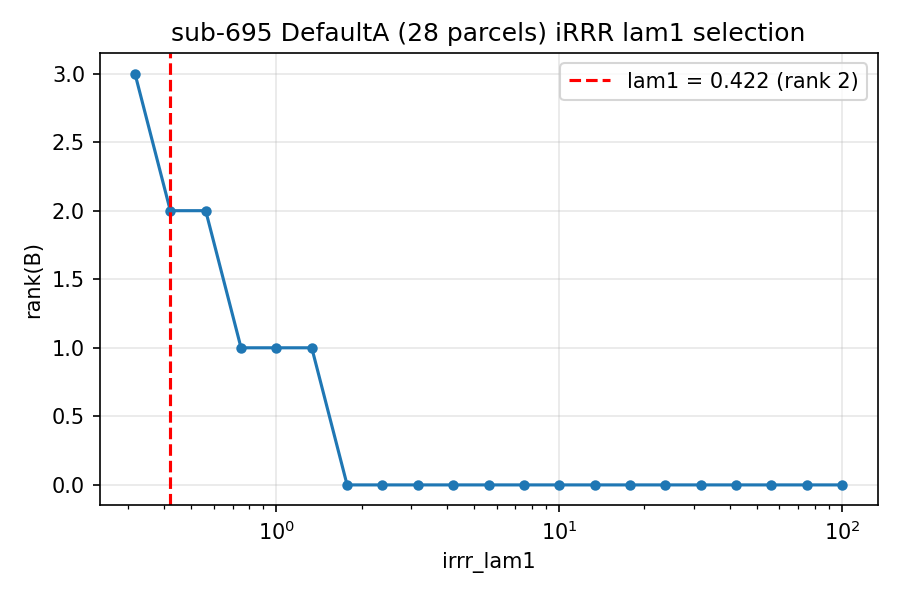

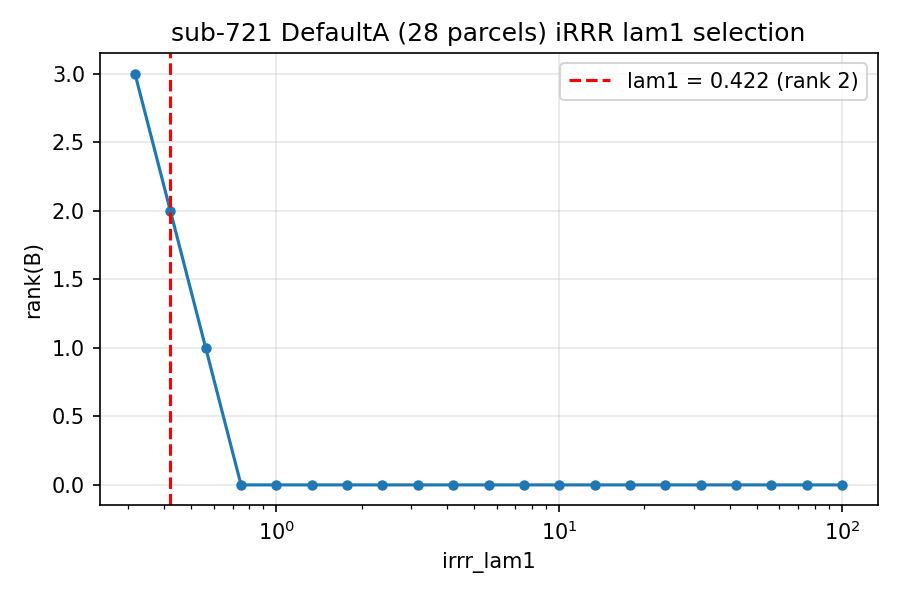

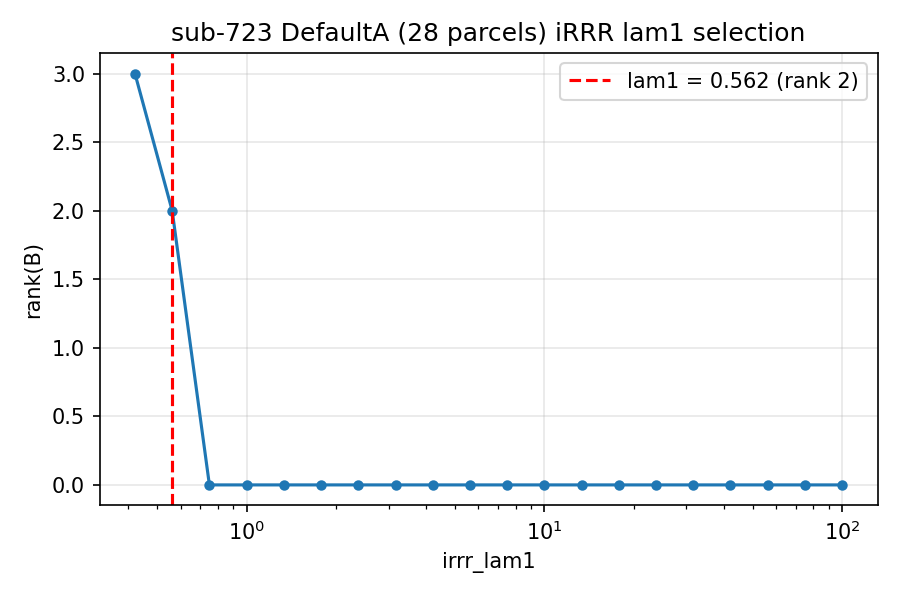

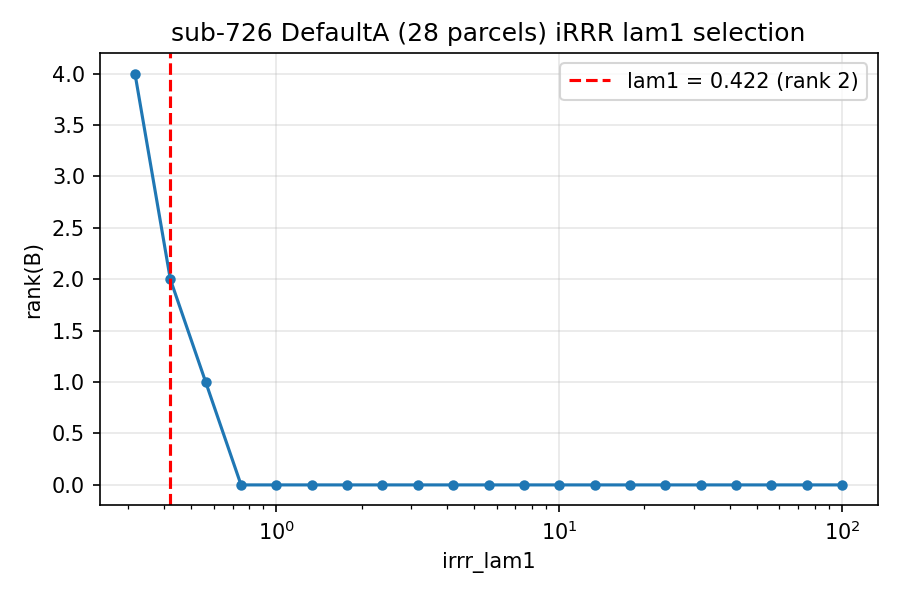

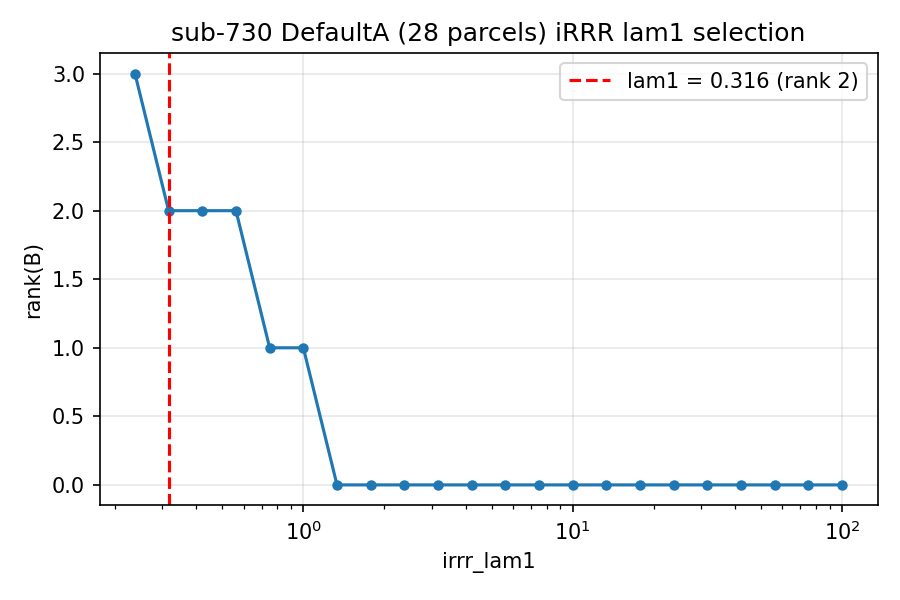

In [21]:
fig, axs = plt.subplots(1, len(ev_subjects), figsize=(3.6 * len(ev_subjects), 3.2), sharex=True, sharey=True)
for ax, s in zip(np.atleast_1d(axs), ev_subjects):
    r = res_ev[s]
    for m in ev_models:
        ax.plot(ev_t, r['hrf_bc'][m].sel(parcel=net_parcels(r['parcels'], select_network)).mean('parcel'),
                color=ev_colors[m], lw=1.6, label=m)
    ax.set_title(f"{s}, {select_network} (λ₁ = {ev_irrr[s]['irrr_lam1'][select_network]:.3g})", fontsize=10)
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5, ls='--')
    ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)
np.atleast_1d(axs)[0].set_ylabel(f'{select_chromo} HRF (M)')
np.atleast_1d(axs)[0].legend(fontsize=8, frameon=False)
fig.supxlabel('Delay (s)')
fig.tight_layout()
fig.savefig(os.path.join(ev_fig_dir, f'subject_hrf_{select_network}.png'), dpi=150)
plt.show()

for s in ev_subjects:
    png = os.path.join(plot_root, s, ev_model_names['AR-iRRR-net'], f'{s}_{select_network}_iRRR_lam1_vs_rank.png')
    if os.path.exists(png):
        display(Image(png, width=420))

## 13. Summary

_To fill in after running the notebook on the full set of subjects._ Points to cover:
- **EEG contribution (section 4):** is the fraction of parcels with p < 0.05 above 0.05, for which trial type and model, and which parcels/networks drive it?
- **Model agreement (sections 5–6):** do AR-IRLS and fixAR-IRLS agree in shape, and how much smaller are the AR-iRRR HRFs?
- **HRF shape (sections 7–8):** is there a consistent peak over the 0–18 s delays, and is anything present at negative delays (EEG after the fNIRS sample, which would point to a non-causal relation or an alignment issue)?
- **mnt-correct vs mnt-incorrect (section 9):** do the two trial types differ, given the much smaller number of incorrect trials?
- **iRRR (sections 3, 10):** how many subjects reach rank 2, and how the two ranks are split between the trial types.
- **Event-based mnt-correct HRF (section 12):** which networks have a significant event-locked HRF, do fixAR-IRLS-net and AR-iRRR-net agree, and does the event-based shape match the EEG-weighted `mnt_correct` HRF?